# MNIST parallel batch effects along PC1
## 1. Purpose / experiment definition
Two disjoint, exactly digit-balanced MNIST batches shift in **opposite directions** along the
first principal component fitted to pooled clean data. For a unit PC1 vector v,
$x_i^\lambda=x_i-\lambda m_{c_i}v$ and $y_j^\lambda=y_j+\lambda m_{d_j}v$.
Constant mode uses m=1; heterogeneous mode samples one signed multiplier per digit from Uniform[-2,2].
The same digit multiplier is shared across batches and held fixed across λ for each corruption seed.
The relative constant-mode shift is 2λ. We never center the multiplier vector or clip analytical data.

Both modes run the same EOT/kNN, embedding and evaluation experiments. Figures compare both modes;
MultiMAP additionally compares centered and uncentered preprocessing. This is a new experiment,
not a replacement for the orthogonal paper figure. Scientific code stays visible in cells.

## 2. Imports and global configuration
Configure construction, corruption, OT, competitors, embedding, evaluation and execution here.
`SMOKE=True` reduces observations, seeds and OT/t-SNE iterations, but leaves MultiMAP optimization
at its native defaults. Loading requires the exact same named configuration; no latest-run selection.
Choose the project environment; MultiMAP runs through its existing isolated interpreter.
Fresh ε₀ ablation: schedule values come from configs/benchmark.toml; λ=0 is also evaluated
for embeddings. No legacy iteration schedule or embedding cache is selected.


In [1]:
from pathlib import Path
from dataclasses import replace, asdict
from functools import partial
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.decomposition import PCA
from torchvision.datasets import MNIST

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from ne_aligned_utils import paper
from ne_aligned_utils.experiments.synthetic import (
    build_mnist_construction,
    compare_construction,
    ExperimentPaths,
    OtConfig,
    EmbeddingConfig,
    EvaluationConfig,
    label_methods,
)
from ne_aligned_utils.experiments.parallel import (
    ParallelConfig,
    ParallelDataConfig,
    ParallelCorruptionConfig,
    ParallelCompetitorsConfig,
    ParallelExperiment,
)
from ne_aligned_utils.evaluation.metrics import compute_kbet, compute_neighbor_purity
from ne_aligned_utils.methods import (
    compute_ot_tsne_embedding_from_plan,
    compute_scanorama_then_tsne_embedding_from_arrays,
    compute_tsne_embedding_from_arrays,
)
from ne_aligned_utils.methods.external.multimap import compute_multimap_embedding_from_arrays
from ne_aligned_utils.paper import layout, registry
from ne_aligned_utils.paper.figures import synthetic as drawing
from ne_aligned_utils.paper.figures import parallel_synthetic as parallel_drawing

paper.use_paper_style()
from dataclasses import asdict, replace


.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Fresh output namespace; construction source is explicit and read-only.
import tomllib
import hashlib
import subprocess
benchmark_definition = tomllib.loads((ROOT / "configs/benchmark.toml").read_text())
benchmark_settings = benchmark_definition["settings"]
TSNE_N_JOBS = int(benchmark_definition["resources"]["cpu"]["threads"])
SOURCE_RUN_DIR = ROOT / "data/mnist/parallel"  # recorded batch construction of the paper's run
source_manifest = json.loads((SOURCE_RUN_DIR / "config.json").read_text())
source_construction = SOURCE_RUN_DIR / "data/construction.npz"
source_audit = pd.read_csv(SOURCE_RUN_DIR / "constant/diagnostics/corruption_audit.csv")
RUN_EXPERIMENT = False
# Loading reads the run this configuration produces; compute it once with RUN_EXPERIMENT = True.
RUN_NAME = None
# Batches when RUN_EXPERIMENT: False loads the recorded construction above. True samples
# MNIST (downloading it into data/torchvision when missing), fits the PCA, and checks both
# against the recorded construction.
BUILD_FROM_MNIST = False
SMOKE = False
SAVE_PAPER_FIGURE = False
RESUME_ABLATION = False  # True resumes only this new run; old runs are never used for outputs.
# Quick-mode runs go to their own folder, so a full run never reads them.
RESULTS_ROOT = ROOT / "results/synthetic_eps_ablation" / ("smoke-v2" if SMOKE else "benchmark-defaults-eps0-20261108-v2")
SOURCE_ROOT = ROOT  # MNIST is read from data/torchvision (or data/)
config = ParallelConfig(
    data=ParallelDataConfig(random_seed=0, n_per_digit=100, modes=("constant", "heterogeneous")),
    corruption=ParallelCorruptionConfig(
        magnitudes=(0.0, 1.0, 4.0, 10.0, 20.0),
        corruption_seeds=(0, 1, 2),
        multiplier_range=(-2.0, 2.0),
        batch_multipliers=(-1.0, 1.0),
    ),
    ot=OtConfig(
        epsilon_policies=("fixed_at_lambda_0", "adaptive_per_magnitude"),
        rel_reg=(1.0,),
        ot_effective_k=15,
        ot_tol=1e-12,
        ot_max_iter=10_000,
    ),
    competitors=ParallelCompetitorsConfig(
        cross_batch_k=15,
        multimap_profile="default",
        multimap_preprocessing=("centered", "uncentered"),
        run_multimap=True,
        run_scanorama_50_tsne=True,
    ),
    # t-SNE schedule: 250 exaggerated + 500 iterations (openTSNE's defaults, as in the benchmark).
    embedding=EmbeddingConfig(
        embedding_seeds=(0, 1, 2), n_epochs=benchmark_settings["visualization_epochs"],
        early_exaggeration_iter=benchmark_settings["tsne_early_exaggeration_iter"]
    ),
    evaluation=EvaluationConfig(kbet_k=15),
)
if SMOKE:
    config = replace(
        config,
        data=replace(config.data, n_per_digit=10),
        corruption=replace(config.corruption, magnitudes=(0.0, 1.0, 10.0), corruption_seeds=(0,)),
        embedding=replace(config.embedding, embedding_seeds=(0,), n_epochs=10, early_exaggeration_iter=10),
    )
plot_config = parallel_drawing.ParallelPlotConfig(
    magnitude=10.0, corruption_seed=0, embedding_seed=0, rel_reg=1.0
)
if (
    plot_config.magnitude not in config.corruption.magnitudes
    or plot_config.corruption_seed not in config.corruption.corruption_seeds
    or plot_config.embedding_seed not in config.embedding.embedding_seeds
    or plot_config.rel_reg not in config.ot.rel_reg
):
    raise ValueError("Choose gallery λ/seeds/rel_reg present in the experiment grid")
mnist_root = SOURCE_ROOT / "data/torchvision"
if not (mnist_root / "MNIST/raw").is_dir() and (SOURCE_ROOT / "data/MNIST/raw").is_dir():
    mnist_root = SOURCE_ROOT / "data"
paths = ExperimentPaths(RESULTS_ROOT, mnist_root, run_name=RUN_NAME, download_mnist=BUILD_FROM_MNIST)
experiment = ParallelExperiment(config, paths)
print("Experiment: MNIST parallel PC1 batch effect · constant and heterogeneous")
print(
    f"Batch signs: {config.corruption.batch_multipliers}; heterogeneous range: {config.corruption.multiplier_range}"
)
print(f"Run: {experiment.run_dir.name}\nResults: {experiment.run_dir}")
print(f"MNIST: {mnist_root} · MultiMAP: {config.competitors.multimap_preprocessing}")
if RUN_EXPERIMENT and experiment.run_dir.exists() and not RESUME_ABLATION:
    raise FileExistsError(f"Fresh run already exists: {experiment.run_dir}. "
                          "Explicitly set RESUME_ABLATION=True or load the saved run.")
if not SMOKE:
    for section in ("data", "corruption"):
        requested = json.loads(json.dumps(asdict(config)[section]))
        recorded = source_manifest["config"][section].copy()
        if section == "corruption":
            assert set(requested.pop("magnitudes")) == {0.0, *recorded.pop("magnitudes")}
        assert requested == recorded, f"Construction settings changed: {section}"
print(f"Ablation outputs: {experiment.run_dir}")
print(f"openTSNE schedule: {config.embedding.early_exaggeration_iter} + {config.embedding.n_epochs}")

def load_selected_ablation(selected_experiment=experiment, expected_run_dir=experiment.run_dir):
    """Load only the run selected above; diagnose stale notebook state before file I/O."""
    if experiment is not selected_experiment or experiment.run_dir != expected_run_dir:
        raise RuntimeError(
            "The experiment object no longer matches this notebook's configuration. "
            "Restart the kernel and Run All, or rerun the imports and configuration cells.")
    manifest_path = expected_run_dir / "config.json"
    if not manifest_path.is_file():
        raise FileNotFoundError(
            f"Selected saved ablation is missing: {manifest_path}. "
            "Check RUN_NAME and the v2 results root in the configuration cell. "
            "Restart the kernel and Run All if an older results path appears. "
            "To compute the run instead, set RUN_EXPERIMENT = True (SMOKE = True for a quick check).")
    return selected_experiment.load_saved()


if not RUN_EXPERIMENT:
    runs = load_selected_ablation()

Experiment: MNIST parallel PC1 batch effect · constant and heterogeneous
Batch signs: (-1.0, 1.0); heterogeneous range: (-2.0, 2.0)
Run: mnist_parallel_batch_effect__seed0__4f85a144
Results: results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v2/mnist_parallel_batch_effect/mnist_parallel_batch_effect__seed0__4f85a144
MNIST: data/torchvision · MultiMAP: ('centered', 'uncentered')
Ablation outputs: results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v2/mnist_parallel_batch_effect/mnist_parallel_batch_effect__seed0__4f85a144
openTSNE schedule: 250 + 500


In [4]:
# Reuse only this session's newly fitted native MultiMAP outputs, whose settings are unchanged.
# Every t-SNE-based output is recomputed with the benchmark's four workers in the v2 namespace.
import shutil
REUSE_FRESH_NATIVE_FITS = False  # Only enable for an explicit resource-only refresh.
if RUN_EXPERIMENT and not SMOKE and REUSE_FRESH_NATIVE_FITS:
    current_fits = (ROOT / "results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v1"
                    / experiment.run_dir.parent.name / experiment.run_dir.name)
    fitted_provenance = json.loads((current_fits / "ablation_manifest.json").read_text())
    assert fitted_provenance["benchmark_settings"] == benchmark_settings
    assert fitted_provenance["source_construction_sha256"] == hashlib.sha256(source_construction.read_bytes()).hexdigest()
    for source in current_fits.glob("*/embeddings/multimap*/*/*/*"):
        if source.is_file() and source.suffix in {".npz", ".json"}:
            target = experiment.run_dir / source.relative_to(current_fits)
            target.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(source, target)
    source_plans = current_fits / "ablation/ot_plans"
    if source_plans.is_dir():
        shutil.copytree(source_plans, experiment.run_dir / "ablation/ot_plans", dirs_exist_ok=True)
    (experiment.run_dir / "benchmark_resource_refresh.json").write_text(json.dumps(dict(
        tsne_n_jobs=TSNE_N_JOBS, reused_fresh_multimap_from=str(current_fits),
        reason="Only t-SNE worker count changed; native MultiMAP and solver inputs/settings are identical"), indent=2))
    print(f"Benchmark openTSNE workers: {TSNE_N_JOBS}; fresh native MultiMAP fits retained from {current_fits.name}")

In [5]:
# Notebook-local cache: only the new rerun's plans are eligible; no legacy method-output reuse.
import hashlib
import time
from ne_aligned_utils.methods import compute_ot_plan
from ne_aligned_utils.methods.ot_affinity import (
    BlockScores, select_four_block, graph_from_pairs,
)

PLAN_TV_ATOL = 1e-7  # Declared comparison tolerance, distinct from Sinkhorn's stop threshold.
plan_directory = experiment.run_dir / "ablation/ot_plans"

if not RUN_EXPERIMENT:
    baseline_eps = runs.cost.loc[(runs.cost.magnitude == 0) &
                                 (runs.cost.epsilon_policy == "fixed_at_lambda_0")]
    experiment.reference_epsilons = {mode: {float(reg): float(part.epsilon.iloc[0])
        for reg, part in group.groupby("rel_reg")}
        for mode, group in baseline_eps.groupby("mode")}

def cached_policy_plan(x0, x1, mode, rel_reg, epsilon_policy, return_artifacts=False):
    settings = dict(mode=mode, rel_reg=float(rel_reg), policy=epsilon_policy,
                    tol=config.ot.ot_tol, max_iter=config.ot.ot_max_iter,
                    epsilon=(experiment.reference_epsilons[mode][float(rel_reg)]
                             if epsilon_policy == "fixed_at_lambda_0" else None))
    key = hashlib.sha256(json.dumps(settings, sort_keys=True).encode())
    for values in (x0, x1):
        key.update(str(values.shape).encode())
        key.update(np.ascontiguousarray(values).tobytes())
    path = plan_directory / f"{epsilon_policy}__rel_reg_{rel_reg:g}__{key.hexdigest()[:16]}.npz"
    if path.is_file():
        with np.load(path, allow_pickle=False) as saved:
            plan = saved["plan"]
            artifacts = json.loads(str(saved["solver_json"]))
    else:
        if not RUN_EXPERIMENT:
            raise FileNotFoundError(f"Exact-input plan cache is missing: {path}. No load-only solve was attempted.")
        kwargs = dict(tol=config.ot.ot_tol, max_iter=config.ot.ot_max_iter, return_artifacts=True)
        if epsilon_policy == "fixed_at_lambda_0":
            kwargs["epsilon"] = settings["epsilon"]
        elif epsilon_policy == "adaptive_per_magnitude":
            kwargs["rel_reg"] = rel_reg
        else:
            raise ValueError(f"Unknown epsilon policy: {epsilon_policy}")
        plan, artifacts = compute_ot_plan(x0, x1, **kwargs)
        artifacts = {k: v for k, v in artifacts.items() if k != "cost_matrix"}
        plan_directory.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(path, plan=plan, solver_json=json.dumps(artifacts, sort_keys=True))
    return (plan, artifacts) if return_artifacts else plan

experiment.compute_policy_plan = cached_policy_plan

def full_plan_record(plan, artifacts, reference, x0, x1, mode, rel_reg, policy):
    other_policy = ("adaptive_per_magnitude" if policy == "fixed_at_lambda_0"
                    else "fixed_at_lambda_0")
    other = experiment.compute_policy_plan(x0, x1, mode, rel_reg, other_policy)
    assert np.isfinite(plan).all() and np.min(plan) >= 0
    tv = float(.5 * np.abs(plan - reference).sum())
    return dict(tv_to_lambda0=tv,
        fixed_vs_adaptive_tv=float(.5 * np.abs(plan - other).sum()),
        median_squared_distance=artifacts["median_squared_distance"],
        sinkhorn_niter=artifacts["sinkhorn_niter"],
        sinkhorn_final_error=artifacts["sinkhorn_final_error"],
        sinkhorn_converged=artifacts["sinkhorn_converged"],
        transported_mass=float(plan.sum()),
        row_marginal_max_error=float(np.max(np.abs(plan.sum(axis=1) - 1 / len(x0)))),
        column_marginal_max_error=float(np.max(np.abs(plan.sum(axis=0) - 1 / len(x1)))),
        tv_within_tolerance=bool(tv <= PLAN_TV_ATOL))

## 3. Construct the clean MNIST batches
Sample 2n distinct source indices per digit, split between batches, then shuffle each batch.
The sampling code is identical to the orthogonal walkthrough. Assertions verify disjointness
and exact balance in compute and load modes.
This rerun restores the recorded construction. Smoke mode takes a balanced ordered subset,
retaining the recorded PCA and corruption; full mode uses every original observation.


In [6]:
if RUN_EXPERIMENT:
    if BUILD_FROM_MNIST:
        construction = build_mnist_construction(
            paths.data_root, source_manifest["config"]["data"]["n_per_digit"],
            config.data.random_seed, download=True)
        with np.load(source_construction, allow_pickle=False) as recorded:
            construction_match = compare_construction(construction, recorded)
        print(f"Built from MNIST; against the recorded construction: {construction_match}.")
    else:
        with np.load(source_construction, allow_pickle=False) as recorded:
            construction = dict(recorded)
    recorded = construction
    (x0_images, x1_images) = (recorded['clean0'], recorded['clean1'])
    (labels0, labels1) = (recorded['labels0'], recorded['labels1'])
    (batch0_indices, batch1_indices) = (recorded['batch0_indices'], recorded['batch1_indices'])
    if SMOKE:
        selected0 = np.sort(np.concatenate([np.flatnonzero(labels0 == c)[:config.data.n_per_digit] for c in range(10)]))
        selected1 = np.sort(np.concatenate([np.flatnonzero(labels1 == c)[:config.data.n_per_digit] for c in range(10)]))
        (x0_images, labels0, batch0_indices) = (x0_images[selected0], labels0[selected0], batch0_indices[selected0])
        (x1_images, labels1, batch1_indices) = (x1_images[selected1], labels1[selected1], batch1_indices[selected1])
    for name in ('x0_images', 'x1_images', 'labels0', 'labels1', 'batch0_indices', 'batch1_indices'):
        setattr(experiment, name, locals()[name])
    experiment.labels = np.r_[labels0, labels1]
else:
    with np.load(experiment.run_dir / 'data/construction.npz', allow_pickle=False) as data:
        (labels0, labels1) = (data['labels0'], data['labels1'])
        (batch0_indices, batch1_indices) = (data['batch0_indices'], data['batch1_indices'])
assert not np.intersect1d(batch0_indices, batch1_indices).size
counts = pd.DataFrame({'batch 0': np.bincount(labels0, minlength=10), 'batch 1': np.bincount(labels1, minlength=10)})
assert counts.eq(config.data.n_per_digit).all().all()
print(f'Each batch: {len(labels0)} observations × 784 pixels; distinct source indices.')
display(counts.T)
if not RUN_EXPERIMENT:
    with np.load(experiment.run_dir / 'data/construction.npz', allow_pickle=False) as data:
        for (name, key) in (('x0_images', 'clean0'), ('x1_images', 'clean1'), ('labels0', 'labels0'), ('labels1', 'labels1'), ('batch0_indices', 'batch0_indices'), ('batch1_indices', 'batch1_indices')):
            setattr(experiment, name, data[key])
    experiment.labels = np.r_[labels0, labels1]

Each batch: 1000 observations × 784 pixels; distinct source indices.


,0,1,2,3,4,5,6,7,8,9
batch 0,100,100,100,100,100,100,100,100,100,100
batch 1,100,100,100,100,100,100,100,100,100,100


## 4. Fit PCA and select the parallel direction
Fit full-SVD PCA to pooled clean observations. Use its first unit component, orienting the largest
absolute loading positively so the sign is deterministic. λ is measured in pixel-space L2 units;
PC1 is not multiplied by its eigenvalue or score standard deviation.
The PCA spectrum highlights PC1; the image shows its signed loading pattern.

In [7]:
if RUN_EXPERIMENT:
    experiment.pca = PCA(n_components=None, svd_solver='full')
    recorded = construction
    experiment.pca.components_ = recorded['pca_components']
    experiment.pca.mean_ = recorded['pca_mean']
    experiment.pca.explained_variance_ = recorded['pca_variance']
    experiment.pca.explained_variance_ratio_ = recorded['pca_variance'] / recorded['pca_variance'].sum()
    experiment.pc1 = experiment.pca.components_[0].copy()
    experiment.pc1 *= np.sign(experiment.pc1[np.argmax(np.abs(experiment.pc1))])
    spectrum = experiment.pca.explained_variance_
else:
    with np.load(experiment.run_dir / 'data/construction.npz', allow_pickle=False) as data:
        (experiment.pc1, spectrum) = (data['pc1'], data['pca_variance'])
assert np.isclose(np.linalg.norm(experiment.pc1), 1.0)
print(f'PC1 explains {spectrum[0] / spectrum.sum():.1%} of clean variance')

PC1 explains 9.6% of clean variance


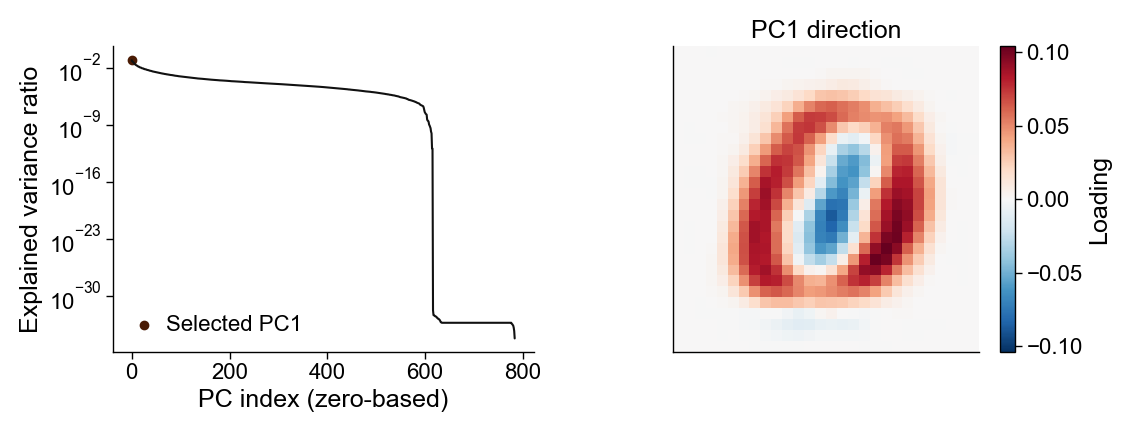

In [8]:
fig, axes = plt.subplots(1, 2, figsize=layout.full_width(2.0), layout="constrained")
axes[0].semilogy(
    np.arange(len(spectrum)), spectrum / spectrum.sum(), color=registry.resolve("joint-pca").color
)
axes[0].scatter(
    [0], [spectrum[0] / spectrum.sum()], color=registry.resolve("ot").color, label="Selected PC1"
)
axes[0].set(xlabel="PC index (zero-based)", ylabel="Explained variance ratio")
axes[0].legend()
limit = np.max(np.abs(experiment.pc1))
image = axes[1].imshow(experiment.pc1.reshape(28, 28), cmap="RdBu_r", vmin=-limit, vmax=limit)
axes[1].set(title="PC1 direction", xticks=[], yticks=[])
fig.colorbar(image, ax=axes[1], label="Loading")
plt.show()

## 5. Construct constant and heterogeneous shifts
Constant mode uses ten ones. Heterogeneous mode draws one signed multiplier per digit and corruption
seed from Uniform[-2,2], then reuses that draw at every λ. This symmetric range gives both forward
and backward class shifts with typical magnitude similar to the constant multiplier 1.
Changing the range once in configuration changes the run fingerprint. No multiplier centering occurs.

In [9]:
if RUN_EXPERIMENT:
    experiment.class_multipliers = {}
    audit_records = []
    for seed in config.corruption.corruption_seeds:
        heterogeneous = np.random.default_rng(seed).uniform(
            *config.corruption.multiplier_range, size=10
        )
        for mode in config.data.modes:
            weights = np.ones(10) if mode == "constant" else heterogeneous.copy()
            experiment.class_multipliers[mode, seed] = weights
            for batch, sign in enumerate(config.corruption.batch_multipliers):
                for digit, multiplier in enumerate(weights):
                    audit_records.append(
                        dict(
                            mode=mode,
                            corruption_seed=seed,
                            batch=batch,
                            digit=digit,
                            class_multiplier=multiplier,
                            batch_sign=sign,
                            pc1_coefficient=sign * multiplier,
                        )
                    )
    experiment.audit = pd.DataFrame(audit_records)
    experiment.initialize_run()
    audit = experiment.audit
else:
    audit = pd.concat(
        [
            pd.read_csv(directory / "diagnostics/corruption_audit.csv")
            for directory in runs.run_dirs.values()
        ],
        ignore_index=True,
    )
    experiment.class_multipliers = {
        (mode, seed): part.query("batch == 0").sort_values("digit").class_multiplier.to_numpy()
        for (mode, seed), part in audit.groupby(["mode", "corruption_seed"])
    }
constant = audit.query("mode == 'constant'")
assert constant.class_multiplier.eq(1).all()
lo, hi = config.corruption.multiplier_range
assert audit.query("mode == 'heterogeneous'").class_multiplier.between(lo, hi).all()
display(audit.groupby(["mode", "batch"])["pc1_coefficient"].agg(["min", "max"]).round(3))

if RUN_EXPERIMENT:
    reference_audit = source_audit
    if source_manifest["variant"] == "parallel_pc1":
        reference_audit = pd.concat([pd.read_csv(SOURCE_RUN_DIR / mode / "diagnostics/corruption_audit.csv")
                                    for mode in config.data.modes], ignore_index=True)
    if SMOKE:
        reference_audit = reference_audit.loc[reference_audit.corruption_seed.isin(config.corruption.corruption_seeds)]
    audit_keys = ["mode", "corruption_seed", "batch", "digit"]
    pd.testing.assert_frame_equal(experiment.audit.sort_values(audit_keys).reset_index(drop=True),
        reference_audit.sort_values(audit_keys).reset_index(drop=True),
        check_dtype=False, check_exact=False, atol=1e-12, rtol=1e-12)
    if not SMOKE and (not BUILD_FROM_MNIST or construction_match == "identical"):
        assert experiment.construction_sha256 == source_manifest["construction_sha256"], "Construction bytes changed"
    from importlib.metadata import version
    provenance = dict(reference_lambda=0.0, source_run=str(SOURCE_RUN_DIR),
        source_construction_sha256=hashlib.sha256(source_construction.read_bytes()).hexdigest(),
        implementation_revision=(subprocess.run(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True, capture_output=True).stdout.strip() or "unknown"),
        benchmark_settings=benchmark_settings, tsne_n_jobs=TSNE_N_JOBS, smoke=SMOKE,
        package_versions={name: version(name) for name in ("numpy", "scipy", "scikit-learn", "opentsne", "POT", "scanorama")},
        notes="Fresh method outputs; recorded construction and order; fixed epsilon at lambda=0")
    (experiment.run_dir / "ablation_manifest.json").write_text(json.dumps(provenance, indent=2, sort_keys=True))


min    max
mode          batch              
constant      0     -1.000 -1.000
              1      1.000  1.000
heterogeneous 0     -1.802  1.934
              1     -1.934  1.802

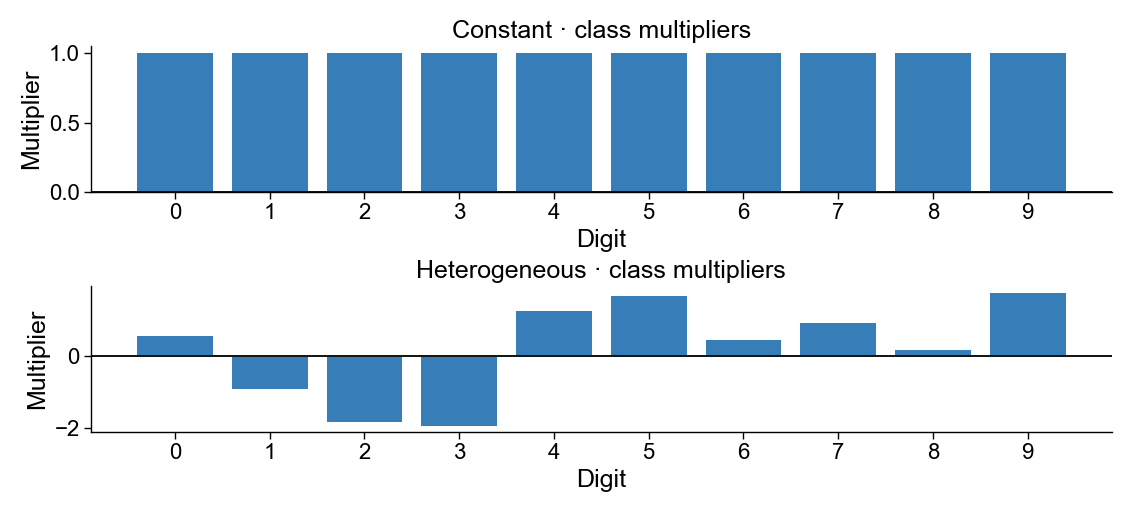

In [10]:
fig, axes = plt.subplots(2, 1, figsize=layout.full_width(2.4), layout="constrained")
for ax, mode in zip(axes, config.data.modes):
    weights = experiment.class_multipliers[mode, plot_config.corruption_seed]
    ax.bar(np.arange(10), weights, color=drawing.GALLERY_BATCH_COLOURS[0])
    ax.axhline(0, color=registry.resolve("joint-pca").color, linewidth=0.7)
    ax.set(
        title=f"{mode.capitalize()} · class multipliers",
        xlabel="Digit",
        ylabel="Multiplier",
        xticks=range(10),
    )
plt.show()

### All digits, both noise modes
Each mode gets its own clean/noisy/clean/noisy grid. Both clean rows show distinct observations;
within each batch the same observation appears before and after its shift. Clipping is display-only.
Change `plot_config.magnitude` to inspect another λ without rerunning an experiment.

Constant · λ=10


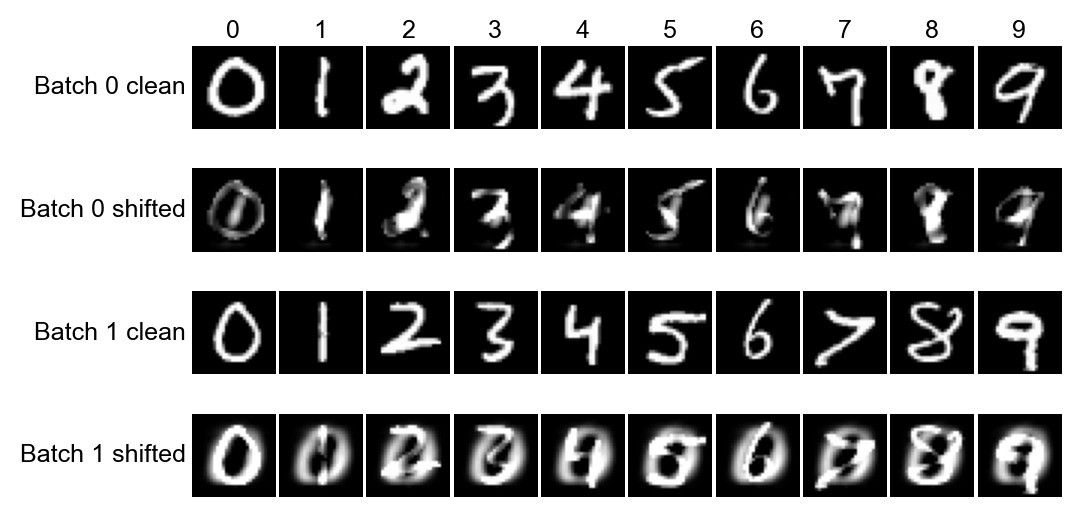

Heterogeneous · λ=10


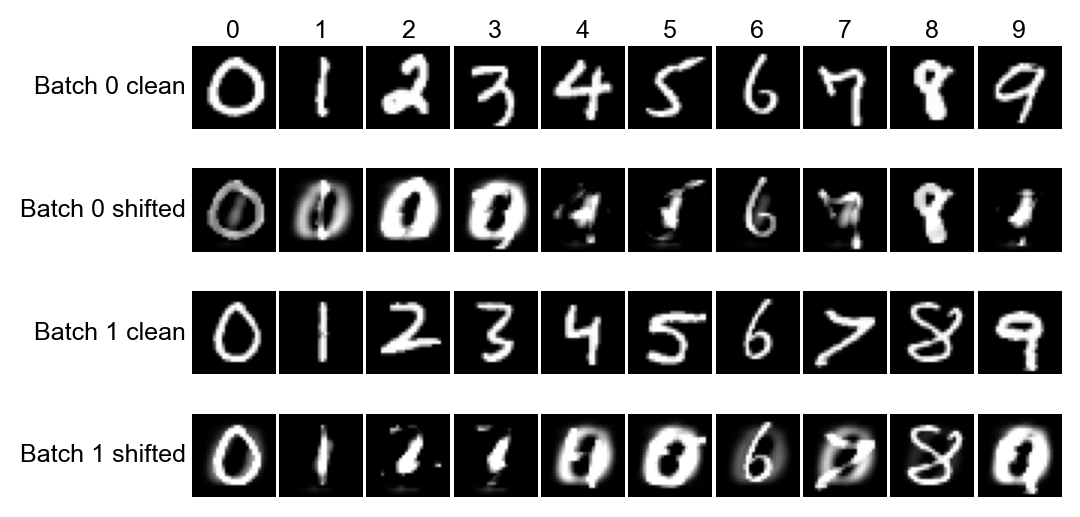

In [11]:
for mode in config.data.modes:
    noisy = experiment.make_batches(mode, plot_config.magnitude, plot_config.corruption_seed)
    representatives = [
        np.array([np.flatnonzero(labels == digit)[0] for digit in range(10)])
        for labels in (experiment.labels0, experiment.labels1)
    ]
    rows = (
        experiment.x0_images[representatives[0]],
        noisy[0][representatives[0]],
        experiment.x1_images[representatives[1]],
        noisy[1][representatives[1]],
    )
    fig, axes = plt.subplots(4, 10, figsize=layout.full_width(2.8), layout="none")
    for row, (examples, name) in enumerate(
        zip(rows, ("Batch 0 clean", "Batch 0 shifted", "Batch 1 clean", "Batch 1 shifted"))
    ):
        for digit, ax in enumerate(axes[row]):
            ax.imshow(np.clip(examples[digit], 0, 1).reshape(28, 28), cmap="gray", vmin=0, vmax=1)
            ax.set(xticks=[], yticks=[])
            for spine in ax.spines.values():
                spine.set_visible(False)
            if row == 0:
                ax.set_title(str(digit))
        axes[row, 0].set_ylabel(name, rotation=0, ha="right", va="center")
    fig.subplots_adjust(left=0.20, right=0.99, bottom=0.03, top=0.89, wspace=0.05, hspace=0.08)
    print(f"{mode.capitalize()} · λ={plot_config.magnitude:g}")
    plt.show()

## 6. Sanity checks / cost decomposition and ε policies
For clean difference d and unit-strength shifts a and b, the cost is
$C^\lambda=C^0+2\lambda d^T(a-b)+\lambda^2\|a-b\|^2$.
Unlike orthogonal noise, the linear interaction generally survives. In constant mode the total
cost change still separates into row and column terms, so balanced OT at fixed ε is invariant.
Heterogeneous class shifts generally introduce nonseparable terms. Adaptive ε is recomputed from
the corrupted costs; fixed ε uses each rel_reg's λ=0 reference.

In [12]:
def parallel_cost_terms(mode, seed, magnitude):
    base0, base1 = experiment.x0_images, experiment.x1_images
    weights = experiment.class_multipliers[mode, seed]
    signs = config.corruption.batch_multipliers
    a = signs[0] * weights[experiment.labels0, None] * experiment.pc1
    b = signs[1] * weights[experiment.labels1, None] * experiment.pc1
    linear = (
        2
        * magnitude
        * (
            np.sum(base0 * a, axis=1)[:, None]
            - a @ base1.T
            - base0 @ b.T
            + np.sum(base1 * b, axis=1)[None, :]
        )
    )
    quadratic = magnitude**2 * experiment.squared_cost(a, b)
    x0, x1 = experiment.make_batches(mode, magnitude, seed)
    clean_cost = experiment.squared_cost(base0, base1)
    observed = experiment.squared_cost(x0, x1)
    error = np.max(np.abs(observed - clean_cost - linear - quadratic))
    change = observed - clean_cost
    interaction = change - change.mean(axis=0) - change.mean(axis=1)[:, None] + change.mean()
    assert error < 1e-8, "Parallel cost decomposition failed"
    if mode == "constant":
        assert np.max(np.abs(interaction)) < 1e-8, "Constant translation must be separable"
        for base, shifted in ((base0, x0), (base1, x1)):
            np.testing.assert_allclose(
                experiment.squared_cost(base, base),
                experiment.squared_cost(shifted, shifted),
                atol=1e-8,
                rtol=1e-10,
            )
    return x0, x1, error, float(np.sqrt(np.mean(interaction**2)))

In [13]:
if RUN_EXPERIMENT:
    experiment.reference_plans = {}
    records = []
    for mode in config.data.modes:
        for rel_reg in config.ot.rel_reg:
            for policy in config.ot.epsilon_policies:
                experiment.reference_plans[mode, rel_reg, policy] = experiment.compute_policy_plan(experiment.x0_images, experiment.x1_images, mode, rel_reg, policy)
        for seed in config.corruption.corruption_seeds:
            for magnitude in tuple(dict.fromkeys((0.0, *config.corruption.magnitudes))):
                (x0, x1, error, interaction) = parallel_cost_terms(mode, seed, magnitude)
                for rel_reg in config.ot.rel_reg:
                    for policy in config.ot.epsilon_policies:
                        (plan, artifacts) = experiment.compute_policy_plan(x0, x1, mode, rel_reg, policy, return_artifacts=True)
                        reference = experiment.reference_plans[mode, rel_reg, policy]
                        records.append(dict(mode=mode, corruption_seed=seed, magnitude=magnitude, rel_reg=rel_reg, epsilon_policy=policy, epsilon=float(artifacts['epsilon']), epsilon_over_reference=float(artifacts['epsilon']) / experiment.reference_epsilons[mode][rel_reg], relative_ot_plan_change=float(np.linalg.norm(plan - reference) / np.linalg.norm(reference)), decomposition_identity_error_max_abs=error, nonseparable_cost_rms=interaction, **full_plan_record(plan, artifacts, reference, x0, x1, mode, rel_reg, policy)))
    experiment.cost_diagnostics = pd.DataFrame(records)
    experiment.save_stage('cost')
    cost = experiment.cost_diagnostics
else:
    cost = runs.cost
control = cost.query("mode == 'constant' and epsilon_policy == 'fixed_at_lambda_0'")
assert len(control) and control.relative_ot_plan_change.max() < 1e-07
assert cost.decomposition_identity_error_max_abs.max() < 1e-08
display(cost.groupby(['mode', 'epsilon_policy'])[['relative_ot_plan_change', 'nonseparable_cost_rms']].max().round(6))

relative_ot_plan_change  \
mode          epsilon_policy                                    
constant      adaptive_per_magnitude                 0.185128   
              fixed_at_lambda_0                      0.000000   
heterogeneous adaptive_per_magnitude                 0.862447   
              fixed_at_lambda_0                      1.571542   

                                      nonseparable_cost_rms  
mode          epsilon_policy                                 
constant      adaptive_per_magnitude               0.000000  
              fixed_at_lambda_0                    0.000000  
heterogeneous adaptive_per_magnitude            1301.385261  
              fixed_at_lambda_0                 1301.385261

### Full plans: ε₀ reference and solver validity
Each policy is compared to its own λ=0 plan using ½Σ|Pλ−P₀|; the policies are also
compared at the same λ. Uniform marginals and total mass are checked without renormalizing.
Sinkhorn's stopping error and the declared plan-distance tolerance are different quantities.
Only constant parallel translation / signal-projected orthogonal inputs are exact invariance controls.
`sinkhorn_niter` retains POT's zero-based last-iteration index.


All λ-sweep plots show only λ > 0. The stored λ=0 plans calibrate ε₀ and remain the internal reference for TV/Jaccard; zero is not an experimental point in these plots.


In [14]:
assert cost.sinkhorn_converged.all(), "Inspect unconverged solves before interpreting plan differences."
assert np.isfinite(cost.tv_to_lambda0).all()
assert (cost.transported_mass - 1).abs().max() < PLAN_TV_ATOL
baseline = cost.loc[cost.magnitude == 0]
assert baseline.tv_to_lambda0.max() <= PLAN_TV_ATOL
assert baseline.fixed_vs_adaptive_tv.max() <= PLAN_TV_ATOL
invariant_mode = "constant" if "constant" in config.data.modes else "projected"
invariant = cost.loc[(cost["mode"] == invariant_mode) & (cost.epsilon_policy == "fixed_at_lambda_0")]
assert invariant.tv_to_lambda0.max() <= PLAN_TV_ATOL
print("Converged solves:", cost.sinkhorn_converged.sum(), "/", len(cost))
print("Maximum invariant-control TV:", invariant.tv_to_lambda0.max())
display(cost.groupby(["mode", "epsilon_policy", "rel_reg"])[
    ["tv_to_lambda0", "fixed_vs_adaptive_tv", "sinkhorn_niter", "sinkhorn_final_error",
     "row_marginal_max_error", "column_marginal_max_error"]].max())
adaptive = cost.loc[cost.epsilon_policy == "adaptive_per_magnitude"]
np.testing.assert_allclose(adaptive.epsilon,
    adaptive.rel_reg * adaptive.median_squared_distance, rtol=1e-12, atol=1e-12)
fixed = cost.loc[cost.epsilon_policy == "fixed_at_lambda_0"]
assert fixed.groupby(["mode", "rel_reg"]).epsilon.nunique().eq(1).all()


Converged solves: 120 / 120
Maximum invariant-control TV: 1.2788649286131032e-15


tv_to_lambda0  \
mode          epsilon_policy         rel_reg                  
constant      adaptive_per_magnitude 1.0       6.693023e-02   
                                     10.0      6.443142e-03   
              fixed_at_lambda_0      1.0       1.278865e-15   
                                     10.0      4.264770e-16   
heterogeneous adaptive_per_magnitude 1.0       3.488755e-01   
                                     10.0      5.423715e-02   
              fixed_at_lambda_0      1.0       6.304159e-01   
                                     10.0      2.871829e-01   

                                              fixed_vs_adaptive_tv  \
mode          epsilon_policy         rel_reg                         
constant      adaptive_per_magnitude 1.0                  0.066930   
                                     10.0                 0.006443   
              fixed_at_lambda_0      1.0                  0.066930   
                                     10.0                 0.006443   
heterogeneous adaptive_per_magnitude 1.0                  0.394353   
                                     10.0                 0.244519   
              fixed_at_lambda_0      1.0                  0.394353   
                                     10.0                 0.244519   

                                              sinkhorn_niter  \
mode          epsilon_policy         rel_reg                   
constant      adaptive_per_magnitude 1.0                  10   
                                     10.0                 10   
              fixed_at_lambda_0      1.0                  10   
                                     10.0                 10   
heterogeneous adaptive_per_magnitude 1.0                  40   
                                     10.0                 10   
              fixed_at_lambda_0      1.0                 330   
                                     10.0                 30   

                                              sinkhorn_final_error  \
mode          epsilon_policy         rel_reg                         
constant      adaptive_per_magnitude 1.0              3.589348e-17   
                                     10.0             3.537491e-17   
              fixed_at_lambda_0      1.0              3.646080e-17   
                                     10.0             3.567536e-17   
heterogeneous adaptive_per_magnitude 1.0              6.780311e-13   
                                     10.0             3.578130e-17   
              fixed_at_lambda_0      1.0              8.316149e-13   
                                     10.0             5.753574e-14   

                                              row_marginal_max_error  \
mode          epsilon_policy         rel_reg                           
constant      adaptive_per_magnitude 1.0                4.336809e-19   
                                     10.0               4.336809e-19   
              fixed_at_lambda_0      1.0                4.336809e-19   
                                     10.0               4.336809e-19   
heterogeneous adaptive_per_magnitude 1.0                4.336809e-19   
                                     10.0               4.336809e-19   
              fixed_at_lambda_0      1.0                4.336809e-19   
                                     10.0               4.336809e-19   

                                              column_marginal_max_error  
mode          epsilon_policy         rel_reg                             
constant      adaptive_per_magnitude 1.0                   4.336809e-18  
                                     10.0                  4.119968e-18  
              fixed_at_lambda_0      1.0                   4.336809e-18  
                                     10.0                  4.553649e-18  
heterogeneous adaptive_per_magnitude 1.0                   4.514379e-14  
                                     10.0                  4.336809e-18  
              fixed_at_lambda_0      1.0                   

In [15]:
def rounded_diagnostic_ylim(ax, *, probability=False):
    """Fit data AND error bars; bounds are multiples of 5 at a suitable decimal scale."""
    siblings = ax.get_shared_y_axes().get_siblings(ax)
    intervals = np.array([other.dataLim.intervaly for other in siblings])
    lo, hi = intervals[:, 0].min(), intervals[:, 1].max()
    if not np.isfinite([lo, hi]).all():
        return
    span = hi - lo
    if span <= max(abs(lo), abs(hi), 1.0) * 1e-12:
        span = .05 if probability else max(abs(lo) * .1, 1e-6)
    quantum = 5 * 10.0 ** (np.floor(np.log10(span)) - 1)
    lower = np.floor((lo - .05 * span) / quantum) * quantum
    upper = np.ceil((hi + .05 * span) / quantum) * quantum
    if probability:
        # Keep mean ± SD visible even if a bounded score's error bar crosses 0 or 1.
        lower = max(0.0, lower) if lo >= 0 else lower
        upper = min(1.0, upper) if hi <= 1 else upper
    if upper <= lower:
        lower, upper = (max(0.0, hi - .05), min(1.0, hi + .05)) if probability else (lo - quantum, hi + quantum)
    ax.set_ylim(float(lower), float(upper))

# Zero is retained in the saved tables for calibration and reference comparisons only.
DISPLAY_MAGNITUDES = tuple(float(x) for x in config.corruption.magnitudes if x > 0)
assert DISPLAY_MAGNITUDES

def sweep_only(frame):
    return frame.loc[frame.magnitude.isin(DISPLAY_MAGNITUDES)].copy()

def policy_panel(ax, frame, metric, ylabel, title, *, bounded=False):
    """Mean ± sample SD over corruption seeds; no lambda-zero observation is plotted."""
    for policy, group in sweep_only(frame).groupby("epsilon_policy", sort=False):
        fixed = policy == "fixed_at_lambda_0"
        if metric == "fixed_vs_adaptive_tv" and fixed:
            continue  # This is one paired comparison, not one curve per policy.
        table = group.groupby("magnitude")[metric].agg(["mean", "std"]).reset_index()
        color = registry.resolve("ot").color
        ax.errorbar(table.magnitude, table["mean"], yerr=table["std"].fillna(0),
            color=color, marker="o" if fixed else "s", markersize=3, capsize=1.5,
            markerfacecolor="white" if fixed else color,
            linestyle=(0, (4, 2.5)) if fixed else "-", linewidth=1.1,
            label=r"Fixed $\epsilon_0$" if fixed else r"Adaptive $\epsilon_\lambda$")
    ax.set(xlabel=r"$\lambda$", ylabel=ylabel, title=title, xticks=DISPLAY_MAGNITUDES)
    if bounded:
        ax.set_ylim(-.03, 1.05)

def ablation_curves(frame, metrics, *, policy_column="epsilon_policy", bounded=False):
    assert policy_column == "epsilon_policy"
    modes = list(config.data.modes)
    fig, axes = plt.subplots(len(modes), len(metrics), squeeze=False,
        figsize=layout.full_width(1.9 * len(modes)), layout="constrained")
    for row, mode in enumerate(modes):
        for ax, (metric, ylabel) in zip(axes[row], metrics):
            policy_panel(ax, frame.loc[frame["mode"] == mode], metric, ylabel,
                mode.replace("projected", "Signal-projected"), bounded=bounded)
        for ax in axes[row]:
            rounded_diagnostic_ylim(ax, probability=bounded)
        axes[row, 0].legend(fontsize=drawing.PANEL_TITLE_PT, handlelength=4)
    return fig


Full-plan comparisons · rel_reg=1 · λ=0 reference


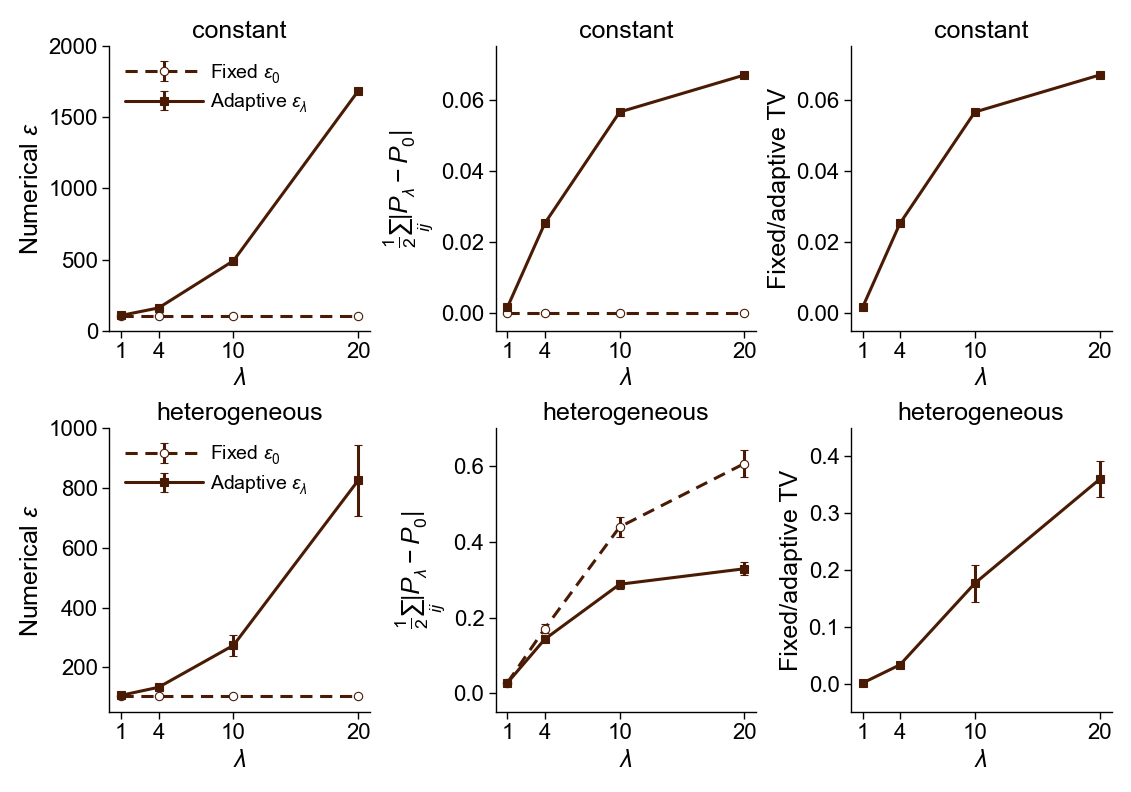

Full-plan comparisons · rel_reg=10 · λ=0 reference


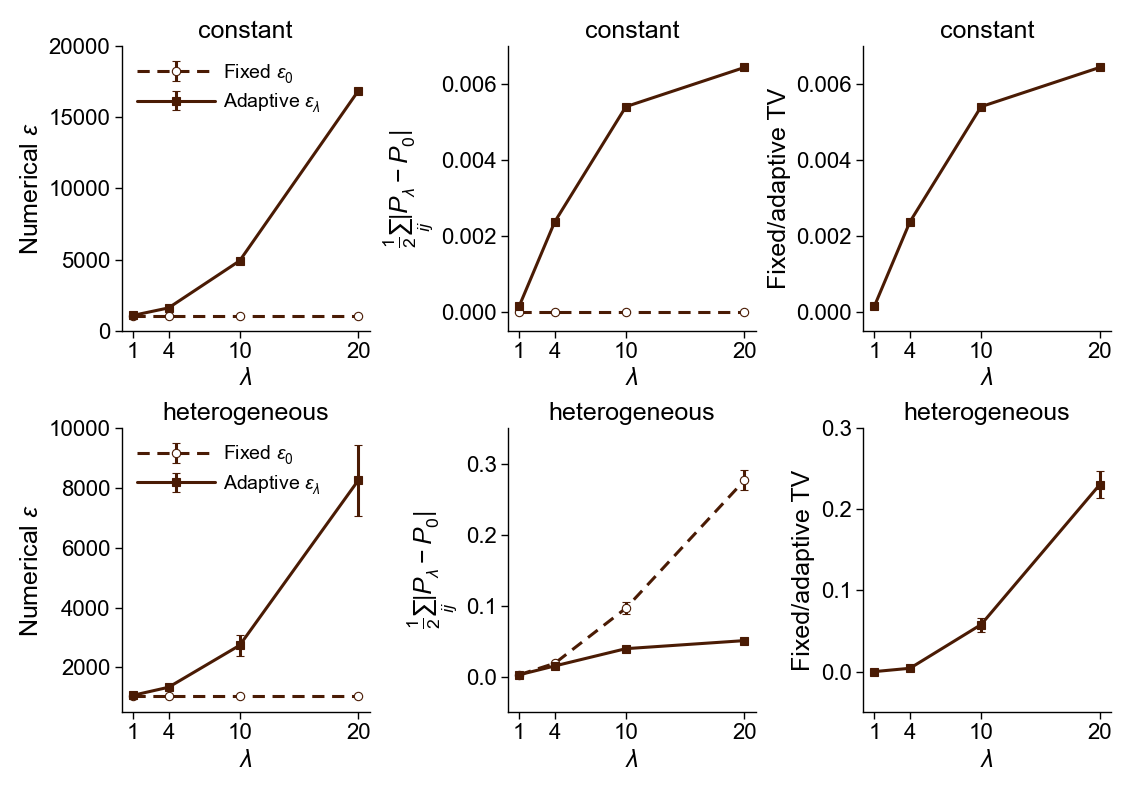

In [16]:
for rel_reg in config.ot.rel_reg:
    selected = cost.loc[np.isclose(cost.rel_reg, rel_reg)]
    print(f"Full-plan comparisons · rel_reg={rel_reg:g} · λ=0 reference")
    ablation_curves(selected, [("epsilon", r"Numerical $\epsilon$"),
        ("tv_to_lambda0", r"$\frac{1}{2}\sum_{ij}|P_\lambda-P_0|$"),
        ("fixed_vs_adaptive_tv", "Fixed/adaptive TV")])
    plt.show()

## 7. Cross-batch affinity experiment: EOT, shared and mutual kNN
Use the same graph diagnostics as the orthogonal experiment. EOT top-k row/column supports,
their union/intersection, shared/mutual kNN purity and nonempty-row coverage are saved for both
noise modes, all corruption seeds, ε policies, rel_reg values and λ (including zero).
Constant translations preserve within-batch neighbors, but can alter cross-batch kNN matching.

In [17]:
def cross_supports(plan):
    k = config.competitors.cross_batch_k
    row = experiment.rectangular_topk_support(plan, k, axis=1)
    column = experiment.rectangular_topk_support(plan, k, axis=0)
    # The current OT-tSNE implementation selects the cross scores directly from P.
    # cross_split uses exactly its proportional quotas/symmetrization, without computing diagonals.
    selection = select_four_block(BlockScores.from_plan(plan, None),
        effective_k=config.ot.ot_effective_k, rule="cross_split", graph_symmetrization="or")
    graph = graph_from_pairs(selection.rows, selection.cols, sum(plan.shape))
    embedded_cross = graph[:plan.shape[0], plan.shape[0]:].toarray() > 0
    return dict(row_top_k=row, column_top_k=column, shared_or=row | column,
                mutual_and=row & column, ot_tsne_cross=embedded_cross)

def edge_overlap_record(plan, reference):
    selected, baseline = cross_supports(plan), cross_supports(reference)
    values = {}
    for graph in selected:
        union = np.count_nonzero(selected[graph] | baseline[graph])
        intersection = np.count_nonzero(selected[graph] & baseline[graph])
        # Two empty supports are identical; the edge count exposes that degenerate case.
        values[f"{graph}_jaccard_to_lambda0"] = float(intersection / union) if union else 1.0
        values[f"{graph}_n_edges"] = int(np.count_nonzero(selected[graph]))
    return values

### Saved inputs for graph diagnostics
The helpers below restore the recorded observations, PCA basis, and seeded corruption vectors.
Cached-plan lookup checks the exact arrays and settings; load-only mode refuses an absent plan.
No OT solve or embedding fit is needed to re-evaluate graph metrics.


In [18]:
# Restore recorded inputs only when cached-plan diagnostics need them.
from ne_aligned_utils.evaluation.hubness import restore_saved_construction

def prepare_cached_plan_inputs(rel_reg=1.0):
    if not RUN_EXPERIMENT:
        restore_saved_construction(experiment)
        if "original" in config.data.modes:
            # Reuse the notebook's exact seeded reconstruction, avoiding CSV float-roundtrip drift.
            with np.load(experiment.run_dir / "data/construction.npz", allow_pickle=False) as data:
                components = data["pca_components"]
            manifest = runs.configs["original"]
            alpha_basis = components[manifest["alpha_tail_pca_indices"]]
            beta_basis = components[manifest["beta_tail_pca_indices"]]
            scales = np.asarray(config.corruption.class_corruption_scales)
            for seed in config.corruption.corruption_seeds:
                scale0 = np.random.default_rng(seed + config.corruption.batch0_scale_seed_offset).permutation(scales)
                scale1 = np.random.default_rng(seed + config.corruption.batch1_scale_seed_offset).permutation(scales)
                experiment.alphas[seed] = make_class_corruptions(alpha_basis, seed, scale0)[0]
                experiment.betas[seed] = make_class_corruptions(
                    beta_basis, seed + config.corruption.batch1_seed_offset, scale1)[0]
        # Read the exact numerical epsilon from the cached lambda-zero solver JSON, not a CSV.
        for mode in config.data.modes:
            zero0, zero1 = experiment.make_batches(mode, 0.0, config.corruption.corruption_seeds[0])
            _, zero_info = experiment.compute_policy_plan(zero0, zero1, mode, rel_reg,
                "adaptive_per_magnitude", return_artifacts=True)
            experiment.reference_epsilons[mode][float(rel_reg)] = zero_info["epsilon"]


In [19]:
if RUN_EXPERIMENT:
    DIAGNOSTIC_MAGNITUDES = tuple(dict.fromkeys((0.0, *experiment.config.corruption.magnitudes)))
    (affinity_records, knn_records) = ([], [])
    for mode in experiment.config.data.modes:
        (base0, base1) = experiment.clean_by_mode[mode]
        same_digit = experiment.labels0[:, None] == experiment.labels1[None, :]
        for corruption_seed in experiment.config.corruption.corruption_seeds:
            for magnitude in DIAGNOSTIC_MAGNITUDES:
                (x0, x1) = experiment.make_batches(mode, magnitude, corruption_seed)
                for rel_reg in experiment.config.ot.rel_reg:
                    for epsilon_policy in experiment.config.ot.epsilon_policies:
                        (plan, artifacts) = experiment.compute_policy_plan(x0, x1, mode, rel_reg, epsilon_policy, return_artifacts=True)
                        reference = experiment.reference_plans[mode, rel_reg, epsilon_policy]
                        row_support = experiment.rectangular_topk_support(plan, experiment.config.competitors.cross_batch_k, axis=1)
                        column_support = experiment.rectangular_topk_support(plan, experiment.config.competitors.cross_batch_k, axis=0)
                        shared_support = row_support | column_support
                        mutual_support = row_support & column_support
                        (row_purity, row_coverage, row_degree) = experiment.support_stats(row_support, experiment.labels0, experiment.labels1)
                        (column_purity, column_coverage, column_degree) = experiment.support_stats(column_support.T, experiment.labels1, experiment.labels0)
                        (shared_purity, shared_coverage, shared_degree) = experiment.support_stats(shared_support, experiment.labels0, experiment.labels1)
                        (mutual_purity, mutual_coverage, mutual_degree) = experiment.support_stats(mutual_support, experiment.labels0, experiment.labels1)
                        affinity_records.append({'mode': mode, 'corruption_seed': corruption_seed, 'magnitude': magnitude, 'rel_reg': rel_reg, 'epsilon_policy': epsilon_policy, 'epsilon': float(artifacts['epsilon']), 'raw_same_digit_mass_fraction': float(plan[same_digit].sum() / plan.sum()), 'relative_ot_plan_change': float(np.linalg.norm(plan - reference) / np.linalg.norm(reference)), 'top_k': experiment.config.competitors.cross_batch_k, 'eot_row_digit_purity': row_purity, 'eot_row_nonempty_row_fraction': row_coverage, 'eot_row_mean_degree': row_degree, 'eot_column_digit_purity': column_purity, 'eot_column_nonempty_row_fraction': column_coverage, 'eot_column_mean_degree': column_degree, 'eot_shared_or_digit_purity': shared_purity, 'eot_shared_or_nonempty_row_fraction': shared_coverage, 'eot_shared_or_mean_degree': shared_degree, 'eot_mutual_and_digit_purity': mutual_purity, 'eot_mutual_and_nonempty_row_fraction': mutual_coverage, 'eot_mutual_and_mean_degree': mutual_degree, **edge_overlap_record(plan, reference)})
                diagnostics = experiment.knn_diagnostics(base0, base1, x0, x1, experiment.config.competitors.cross_batch_k)
                knn_records.append({'mode': mode, 'corruption_seed': corruption_seed, 'magnitude': magnitude, 'k': experiment.config.competitors.cross_batch_k, **diagnostics})
    experiment.affinity_diagnostics = pd.DataFrame(affinity_records)
    experiment.knn_diagnostics_table = pd.DataFrame(knn_records)
    experiment.save_stage('affinity')
    (affinity, knn) = (experiment.affinity_diagnostics, experiment.knn_diagnostics_table)
else:
    (affinity, knn) = (runs.affinity, runs.knn)

### Symmetric cross-batch graph purity
Re-evaluate the saved plans using the same row/column top-15 union graph. For its rectangular
support $A$, calculate the unweighted same-digit neighbor fraction at every batch-0 node using
rows of $A$, and at every batch-1 node using rows of $A^\top$. Average within each batch,
then give the two batches equal weight:
$Q_{\rm sym}=\frac12(Q_{0\to1}+Q_{1\to0})$.
The union graph covers every node, so neither batch has undefined node scores. This changes
only how graph purity is aggregated: the plans, selected edges, embedding metrics, and Jaccard
comparisons are unchanged. Appendix purity panels below use this symmetric score. The original
one-sided experiment artifacts remain intact; the main graph panels now also use symmetric scores, while embedding metrics are unchanged; both directional scores
and the new symmetric score are saved separately for audit.


In [20]:
# Re-score graph purity only: all plans come from this run's exact-input cache in load mode.
GRAPH_PURITY_K = config.competitors.cross_batch_k
purity_records = []
for rel_reg in config.ot.rel_reg:
    prepare_cached_plan_inputs(rel_reg)
    for mode in config.data.modes:
        for seed in config.corruption.corruption_seeds:
            for magnitude in config.corruption.magnitudes:
                x0, x1 = experiment.make_batches(mode, magnitude, seed)
                for policy in config.ot.epsilon_policies:
                    plan = experiment.compute_policy_plan(x0, x1, mode, rel_reg, policy)
                    rows = experiment.rectangular_topk_support(plan, GRAPH_PURITY_K, axis=1)
                    columns = experiment.rectangular_topk_support(plan, GRAPH_PURITY_K, axis=0)
                    support = rows | columns
                    q01, coverage0, _ = experiment.support_stats(support, experiment.labels0, experiment.labels1)
                    q10, coverage1, _ = experiment.support_stats(support.T, experiment.labels1, experiment.labels0)
                    assert coverage0 == coverage1 == 1.0
                    purity_records.append(dict(mode=mode, magnitude=magnitude, corruption_seed=seed,
                        rel_reg=float(rel_reg), epsilon_policy=policy,
                        graph_purity_batch0=q01, graph_purity_batch1=q10,
                        eot_shared_or_symmetric_digit_purity=.5 * (q01 + q10)))
symmetric_graph_purity = pd.DataFrame(purity_records)
purity_keys = ["mode", "magnitude", "corruption_seed", "rel_reg", "epsilon_policy"]
purity_columns = ["graph_purity_batch0", "graph_purity_batch1", "eot_shared_or_symmetric_digit_purity"]
assert symmetric_graph_purity[purity_columns].ge(0).all().all()
assert symmetric_graph_purity[purity_columns].le(1).all().all()
# Confirm that the old, batch-0 calculation has been reproduced before changing the plotted score.
purity_check = symmetric_graph_purity.merge(
    affinity[purity_keys + ["eot_shared_or_digit_purity"]], on=purity_keys, validate="one_to_one")
assert len(purity_check) == len(affinity)
assert np.allclose(purity_check.graph_purity_batch0, purity_check.eot_shared_or_digit_purity,
                   atol=1e-12, rtol=1e-10)
affinity = affinity.drop(columns=purity_columns, errors="ignore").merge(
    symmetric_graph_purity, on=purity_keys, validate="one_to_one")
symmetric_purity_summary = symmetric_graph_purity.groupby(
    ["mode", "magnitude", "rel_reg", "epsilon_policy"]
)[purity_columns].agg(["mean", "std"]).reset_index()
purity_dir = experiment.run_dir / "ablation/symmetric_graph_purity"
purity_dir.mkdir(parents=True, exist_ok=True)
symmetric_graph_purity.to_csv(purity_dir / "cross_batch_graph_purity_raw.csv", index=False)
symmetric_purity_summary.to_csv(purity_dir / "cross_batch_graph_purity_summary.csv", index=False)
(purity_dir / "config.json").write_text(json.dumps(dict(schema_version=1,
    run_dir=str(experiment.run_dir), graph="union_of_row_and_column_top_k", k=GRAPH_PURITY_K,
    aggregation="equal_batch_average_of_unweighted_node_purity", rel_reg=list(config.ot.rel_reg),
    epsilon_policies=list(config.ot.epsilon_policies), magnitudes=list(config.corruption.magnitudes),
    corruption_seeds=list(config.corruption.corruption_seeds),
    construction_sha256=json.loads((experiment.run_dir / "config.json").read_text())["construction_sha256"]), indent=2))
print(f"Re-scored {len(symmetric_graph_purity)} cached plans; directional and symmetric purity: {purity_dir}")
display(symmetric_purity_summary.loc[(symmetric_purity_summary.magnitude == max(DISPLAY_MAGNITUDES)) &
    np.isclose(symmetric_purity_summary.rel_reg, 1.0)].round(4))


# Re-score the shared and mutual kNN graphs with the identical two-batch averaging rule.
knn_purity_records = []
prepare_cached_plan_inputs(1.0)
for mode in config.data.modes:
    for seed in config.corruption.corruption_seeds:
        for magnitude in config.corruption.magnitudes:
            x0, x1 = experiment.make_batches(mode, magnitude, seed)
            forward = experiment.directed_knn(x0, x1, GRAPH_PURITY_K)
            backward = experiment.directed_knn(x1, x0, GRAPH_PURITY_K)
            support01 = np.zeros((len(x0), len(x1)), dtype=bool)
            support10 = np.zeros_like(support01)
            support01[np.arange(len(x0))[:, None], forward] = True
            support10[backward, np.arange(len(x1))[:, None]] = True
            record = dict(mode=mode, magnitude=magnitude, corruption_seed=seed, k=GRAPH_PURITY_K)
            for graph, support in (("shared", support01 | support10), ("mutual", support01 & support10)):
                q01, cov0, _ = experiment.support_stats(support, experiment.labels0, experiment.labels1)
                q10, cov1, _ = experiment.support_stats(support.T, experiment.labels1, experiment.labels0)
                record.update({f"{graph}_purity_batch0": q01, f"{graph}_purity_batch1": q10,
                    f"{graph}_symmetric_correct_class_neighbor_fraction": .5 * (q01 + q10),
                    f"{graph}_coverage_batch0": cov0, f"{graph}_coverage_batch1": cov1})
            knn_purity_records.append(record)
symmetric_knn_purity = pd.DataFrame(knn_purity_records)
knn_keys = ["mode", "magnitude", "corruption_seed", "k"]
for graph in ("shared", "mutual"):
    check = symmetric_knn_purity.merge(knn[knn_keys + [f"{graph}_correct_class_neighbor_fraction"]],
                                       on=knn_keys, validate="one_to_one")
    assert len(check) == len(knn)
    assert np.allclose(check[f"{graph}_purity_batch0"],
        check[f"{graph}_correct_class_neighbor_fraction"], atol=1e-12, equal_nan=True)
knn_new_columns = list(symmetric_knn_purity.columns.difference(knn_keys))
knn = knn.drop(columns=knn_new_columns, errors="ignore").merge(
    symmetric_knn_purity, on=knn_keys, validate="one_to_one")
symmetric_knn_purity.to_csv(purity_dir / "cross_batch_knn_purity_raw.csv", index=False)
print("Saved symmetric shared/mutual kNN purity; isolated nodes are excluded separately within each batch.")


Re-scored 120 cached plans; directional and symmetric purity: results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v2/mnist_parallel_batch_effect/mnist_parallel_batch_effect__seed0__4f85a144/ablation/symmetric_graph_purity


mode magnitude rel_reg          epsilon_policy  \
                                                              
16       constant      20.0     1.0  adaptive_per_magnitude   
17       constant      20.0     1.0       fixed_at_lambda_0   
36  heterogeneous      20.0     1.0  adaptive_per_magnitude   
37  heterogeneous      20.0     1.0       fixed_at_lambda_0   

   graph_purity_batch0         graph_purity_batch1          \
                  mean     std                mean     std   
16              0.6805  0.0000              0.6795  0.0000   
17              0.6856  0.0000              0.6854  0.0000   
36              0.0750  0.0734              0.0619  0.0638   
37              0.1032  0.0527              0.1020  0.0516   

   eot_shared_or_symmetric_digit_purity          
                                   mean     std  
16                               0.6800  0.0000  
17                               0.6855  0.0000  
36                               0.0684  0.0686  
37                               0.1026  0.0502

Saved symmetric shared/mutual kNN purity; isolated nodes are excluded separately within each batch.


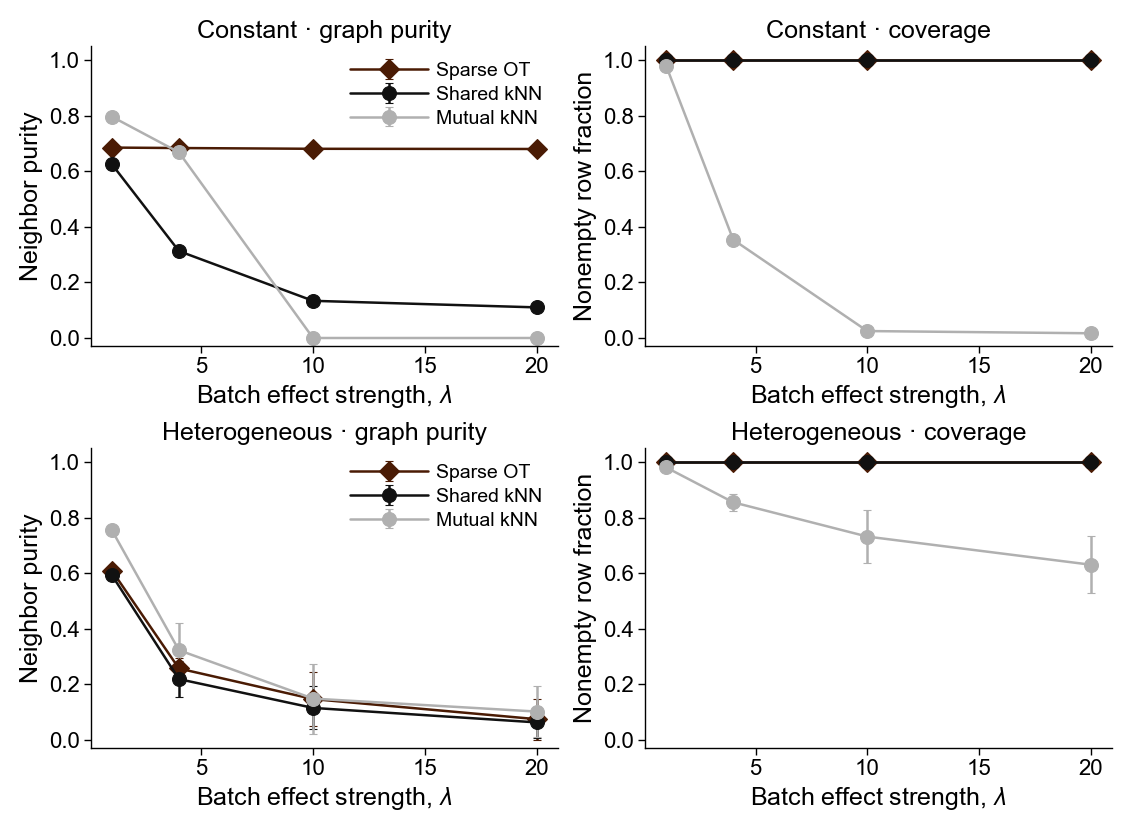

shared_correct_class_neighbor_fraction  \
mode          magnitude                                           
constant      1.0                                         0.625   
              4.0                                         0.313   
              10.0                                        0.134   
              20.0                                        0.110   
heterogeneous 1.0                                         0.593   
              4.0                                         0.219   
              10.0                                        0.116   
              20.0                                        0.063   

                         mutual_correct_class_neighbor_fraction  \
mode          magnitude                                           
constant      1.0                                         0.797   
              4.0                                         0.668   
              10.0                                        0.000   
              20.0                                        0.000   
heterogeneous 1.0                                         0.755   
              4.0                                         0.323   
              10.0                                        0.149   
              20.0                                        0.102   

                         mutual_nonempty_row_fraction  \
mode          magnitude                                 
constant      1.0                               0.980   
              4.0                               0.354   
              10.0                              0.025   
              20.0                              0.017   
heterogeneous 1.0                               0.981   
              4.0                               0.856   
              10.0                              0.732   
              20.0                              0.631   

                         within_batch_knn_edge_preservation  
mode          magnitude                                      
constant      1.0                                     1.000  
              4.0                                     1.000  
              10.0                                    1.000  
              20.0                                    1.000  
heterogeneous 1.0                                     0.899  
              4.0                                     0.770  
              10.0                                    0.735  
              20.0                                    0.717

In [21]:
parallel_drawing.affinity_figure(sweep_only(affinity), sweep_only(knn), config.data.modes, plot_config.rel_reg)
plt.show()
display(
    sweep_only(knn).groupby(["mode", "magnitude"])[[
        "shared_correct_class_neighbor_fraction",
        "mutual_correct_class_neighbor_fraction",
        "mutual_nonempty_row_fraction",
        "within_batch_knn_edge_preservation",
    ]].mean().round(3)
)

### Edge stability against zero
Compare each policy's graph at λ with its own λ=0 reference using
$J=|E_\lambda\cap E_0|/|E_\lambda\cup E_0|$. Sparse OT uses the row/column top-15 union;
the OT-tSNE cross-affinity support follows the method's split neighbor budget. Jaccard measures
edge membership, not weight agreement or digit correctness. Zero remains an internal reference;
only positive λ values are plotted. Full directed/union/intersection diagnostics remain saved.


shared_or_jaccard_to_lambda0  \
mode          epsilon_policy         rel_reg                                 
constant      adaptive_per_magnitude 1.0                             0.942   
                                     10.0                            0.993   
              fixed_at_lambda_0      1.0                             1.000   
                                     10.0                            1.000   
heterogeneous adaptive_per_magnitude 1.0                             0.058   
                                     10.0                            0.038   
              fixed_at_lambda_0      1.0                             0.073   
                                     10.0                            0.057   

                                              ot_tsne_cross_jaccard_to_lambda0  
mode          epsilon_policy         rel_reg                                    
constant      adaptive_per_magnitude 1.0                                 0.941  
                                     10.0                                0.995  
              fixed_at_lambda_0      1.0                                 1.000  
                                     10.0                                1.000  
heterogeneous adaptive_per_magnitude 1.0                                 0.051  
                                     10.0                                0.033  
              fixed_at_lambda_0      1.0                                 0.065  
                                     10.0                                0.049

Cross-batch supports · rel_reg=1


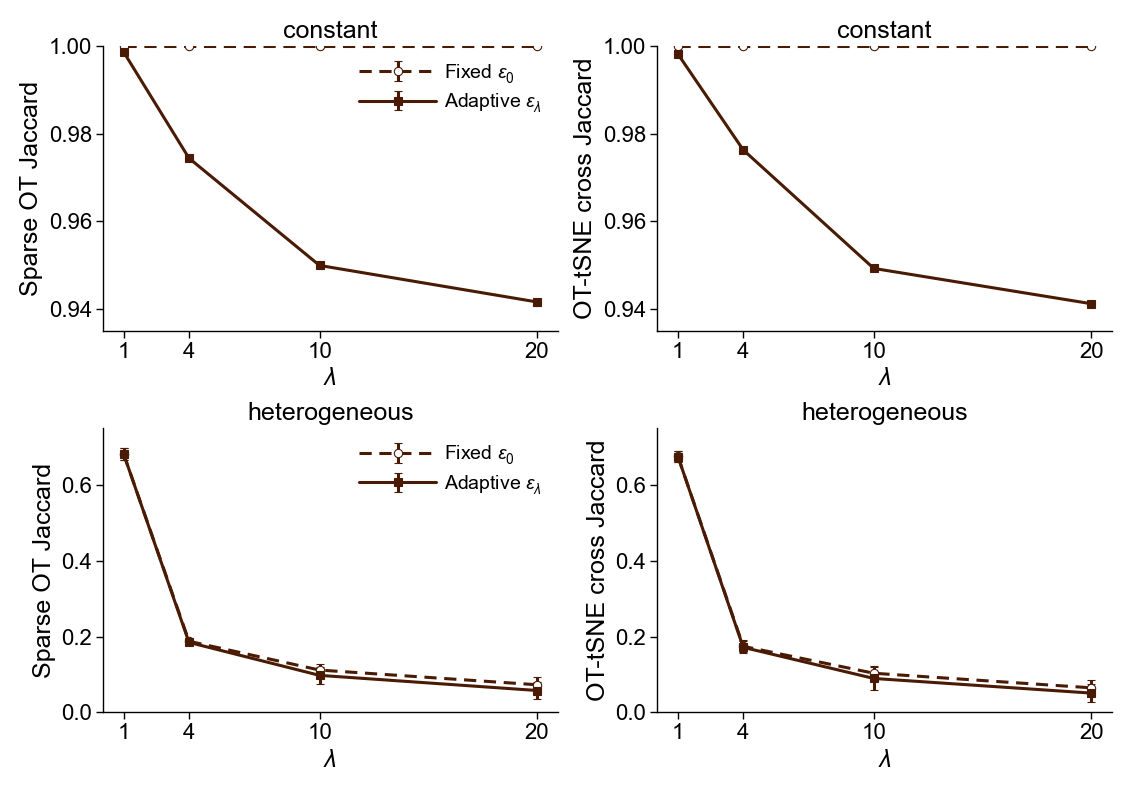

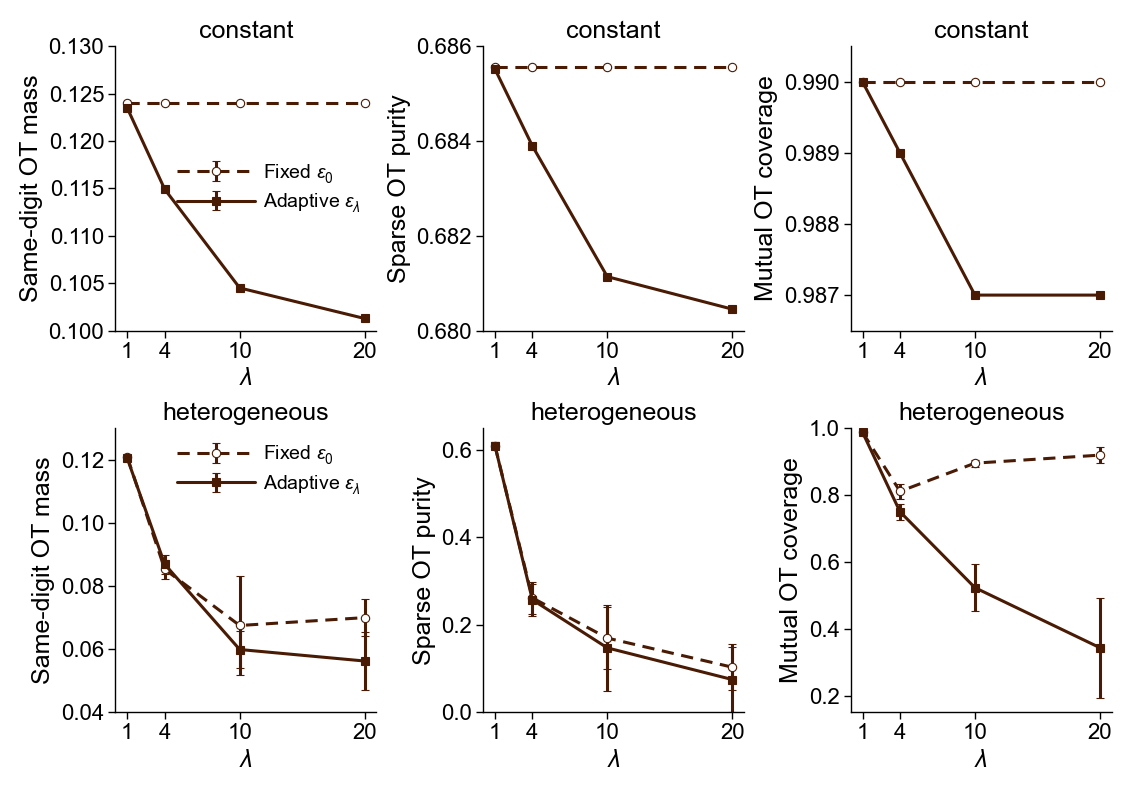

Cross-batch supports · rel_reg=10


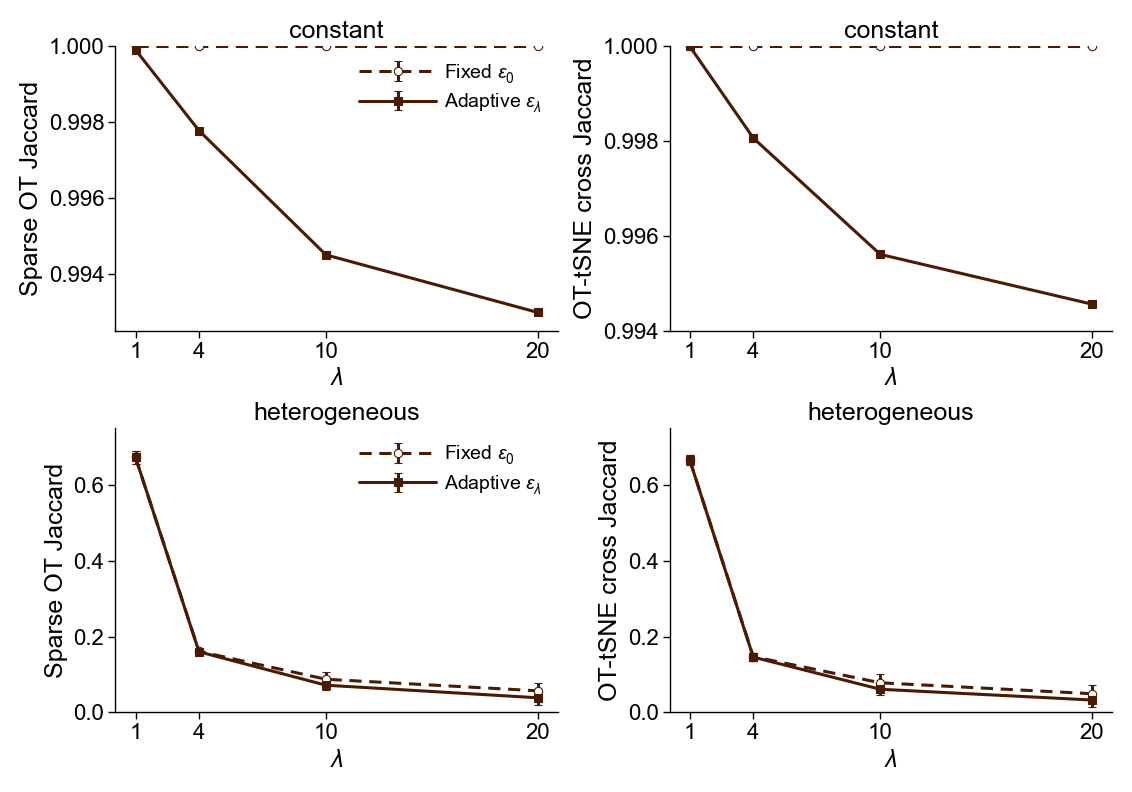

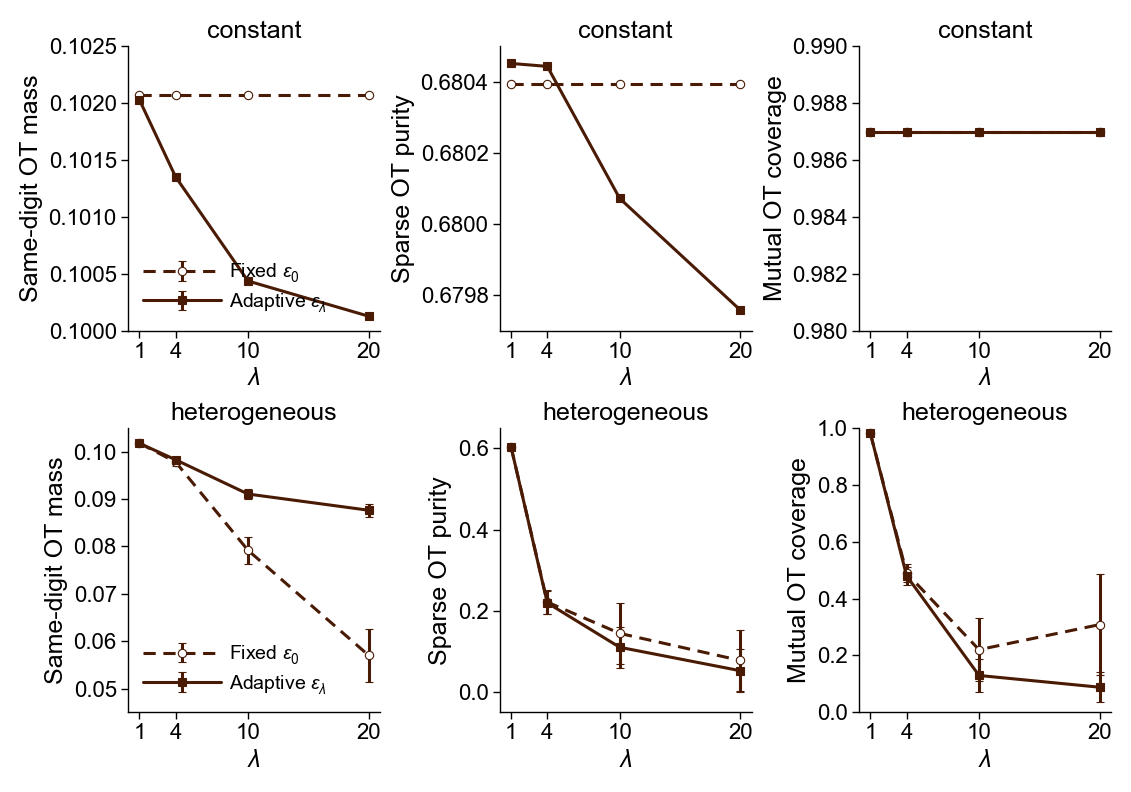

In [22]:
jaccard_columns = [c for c in affinity if c.endswith("_jaccard_to_lambda0")]
assert affinity[jaccard_columns].ge(0).all().all() and affinity[jaccard_columns].le(1).all().all()
assert affinity.loc[affinity.magnitude == 0, jaccard_columns].eq(1).all().all()
display(affinity.loc[affinity.magnitude == max(config.corruption.magnitudes)]
    .groupby(["mode", "epsilon_policy", "rel_reg"])[["shared_or_jaccard_to_lambda0", "ot_tsne_cross_jaccard_to_lambda0"]].mean().round(3))
for rel_reg in config.ot.rel_reg:
    selected = affinity.loc[np.isclose(affinity.rel_reg, rel_reg)]
    print(f"Cross-batch supports · rel_reg={rel_reg:g}")
    ablation_curves(selected, [("shared_or_jaccard_to_lambda0", "Sparse OT Jaccard"),
        ("ot_tsne_cross_jaccard_to_lambda0", "OT-tSNE cross Jaccard")], bounded=True)
    plt.show()
    ablation_curves(selected, [("raw_same_digit_mass_fraction", "Same-digit OT mass"),
        ("eot_shared_or_digit_purity", "Sparse OT purity"),
        ("eot_mutual_and_nonempty_row_fraction", "Mutual OT coverage")], bounded=True)
    plt.show()

### Receiving-side hubness and coverage (cross-batch k=15)
For each receiving point j, count distinct opposite-batch senders: Nₖ(j). Histograms at λ=10
normalize each graph/batch/seed by its own mean, including zero-degree points. The y-axis
is logarithmic to show sparse tails; the x-axis stays linear so anti-hubs at zero remain visible. Tables report
anti-hub fraction, maximum occurrence, and population skewness (undefined for constant counts).
The λ=10 summary averages anti-hub fractions/skewness over seeds and takes the largest
per-seed maximum. Raw per-seed values are saved. Coverage is the fraction with Nₖ≥1,
with mean ± sample SD over the existing corruption seeds.
Directed 0→1 has receiving batch 1 only; directed 1→0 has receiving batch 0 only.

We use the same input representation and Euclidean neighbors as the purity analysis. Mutual/shared
kNN are the intersection/union of both directed selections. Sparsified OT is the **cross-batch
row-top-15/column-top-15 union used in the affinity purity comparison**, at the diagnostic rel_reg
for each ε policy. This is not the embedding's four-block effective-k graph. Symmetrized shared kNN
and this OT support guarantee positive degree on both sides: their coverage is structurally one,
although their in-degree distributions can be uneven. Heavy tails or concentration near 1 are
hypotheses to inspect, not imposed results. Independent normalization avoids conflating unequal
batch sizes with hubness; no within-batch edges or affinity weights enter the counts.

`COMPUTE_HUBNESS=True` computes only these graph diagnostics, including from a saved construction;
it does not run embeddings or change seeds/λ values. Otherwise read a compatible saved diagnostic.
MultiMAP connectivities and Scanorama MNN pairs were not retained in the existing artifact
interfaces, so those optional receiving-graph diagnostics are skipped (coordinates are not graphs).

This ablation displays **both** fixed-at-λ=0 and adaptive ε separately at the selected
rel_reg. kNN controls are identical across policies. Coverage aggregation filters by policy
before taking seed means/SDs, so it never mixes fixed and adaptive graph measurements.


**Why two batches for an undirected graph?** For a cross-batch support matrix $A$, batch-0 degrees
are $d_i^{(0)}=\sum_j A_{ij}$ and batch-1 degrees are $d_j^{(1)}=\sum_i A_{ij}$.
Each undirected edge contributes one neighbor to each endpoint. The histograms show these two
node populations separately, not a pooled distribution and not two contributions to one node.
For directed $0\to1$ kNN only batch 1 receives; for $1\to0$ only batch 0 receives.

**Coverage** for batch $b$ is $\frac{1}{n_b}\sum_i\mathbf{1}[d_i^{(b)}\ge1]$;
coverage 0.8 means 20% of that batch has no cross-batch neighbor. It measures contact, not digit
correctness or uniformity of degrees. Shared kNN (union of both directions) and Sparse OT
(union of row/column top-15 supports) cover both batches by construction. Mutual kNN can leave
isolated nodes. Thus flat coverage 1 for shared/Sparse OT is expected; the degree histograms
show whether many edges nevertheless concentrate on a few nodes. Curves show mean ± SD over
corruption seeds, separately by receiving batch. MultiMAP connectivities and Scanorama MNN pairs
are not present in the saved artifacts, so these methods are omitted here.


In [23]:
from ne_aligned_utils.evaluation.hubness import (
    cross_batch_occurrences, occurrence_statistics, summarize_coverage, restore_saved_construction,
)
from ne_aligned_utils.paper.figures.hubness import occurrence_histograms, receiving_coverage_figure

COMPUTE_HUBNESS = RUN_EXPERIMENT  # Reuses this ablation's plan cache; no new embedding runs.
HUBNESS_K, HUBNESS_MAGNITUDE = 15, 10.0
hubness_dir = experiment.run_dir / "ablation/hubness"
hubness_settings = dict(schema="paired_eps0_cross_batch_topk_union_v1", k=HUBNESS_K,
    rel_reg=plot_config.rel_reg, epsilon_policies=list(config.ot.epsilon_policies),
    histogram_magnitude=HUBNESS_MAGNITUDE,
    construction_sha256=json.loads((experiment.run_dir / "config.json").read_text())["construction_sha256"])
hubness_stats = hubness_points = None

In [24]:
if COMPUTE_HUBNESS:
    prepare_cached_plan_inputs(plot_config.rel_reg)
    hubness_records, histogram_records = [], []
    for mode in config.data.modes:
        for corruption_seed in config.corruption.corruption_seeds:
            for magnitude in config.corruption.magnitudes:
                x0, x1 = experiment.make_batches(mode, magnitude, corruption_seed)
                forward = experiment.directed_knn(x0, x1, HUBNESS_K)
                backward = experiment.directed_knn(x1, x0, HUBNESS_K)
                for policy in config.ot.epsilon_policies:
                    plan = experiment.compute_policy_plan(x0, x1, mode, plot_config.rel_reg, policy)
                    points = cross_batch_occurrences(forward, backward,
                        experiment.rectangular_topk_support(plan, HUBNESS_K, axis=1),
                        experiment.rectangular_topk_support(plan, HUBNESS_K, axis=0))
                    metadata = dict(mode=mode, magnitude=magnitude, corruption_seed=corruption_seed,
                                    k=HUBNESS_K, rel_reg=plot_config.rel_reg, epsilon_policy=policy)
                    hubness_records.append(occurrence_statistics(points).assign(**metadata))
                    if magnitude == HUBNESS_MAGNITUDE:
                        histogram_records.append(points.assign(**metadata))
            print(f"Paired receiving diagnostics: {mode}, corruption seed {corruption_seed}")
    hubness_stats = pd.concat(hubness_records, ignore_index=True)
    hubness_points = (pd.concat(histogram_records, ignore_index=True) if histogram_records
                      else pd.DataFrame(columns=[*points.columns, *metadata]))
    hubness_dir.mkdir(parents=True, exist_ok=True)
    hubness_stats.to_csv(hubness_dir / "receiving_coverage_metrics_raw.csv", index=False)
    hubness_points.to_csv(hubness_dir / "k_occurrence_lambda10.csv", index=False)
    hubness_summary = pd.concat([summarize_coverage(part).assign(epsilon_policy=policy)
        for policy, part in hubness_stats.groupby("epsilon_policy")], ignore_index=True)
    hubness_summary.to_csv(hubness_dir / "receiving_coverage_metrics_summary.csv", index=False)
    (hubness_dir / "config.json").write_text(json.dumps(hubness_settings, indent=2, sort_keys=True))
elif (hubness_dir / "config.json").is_file():
    if json.loads((hubness_dir / "config.json").read_text()) != hubness_settings:
        raise ValueError("Saved hubness selection differs; explicitly recompute this diagnostic.")
    hubness_stats = pd.read_csv(hubness_dir / "receiving_coverage_metrics_raw.csv")
    hubness_points = pd.read_csv(hubness_dir / "k_occurrence_lambda10.csv")
else:
    print("No paired hubness cache yet. Set COMPUTE_HUBNESS=True to use this run's stored plans.")

Receiving diagnostics · Fixed ε at λ=0 · rel_reg=1


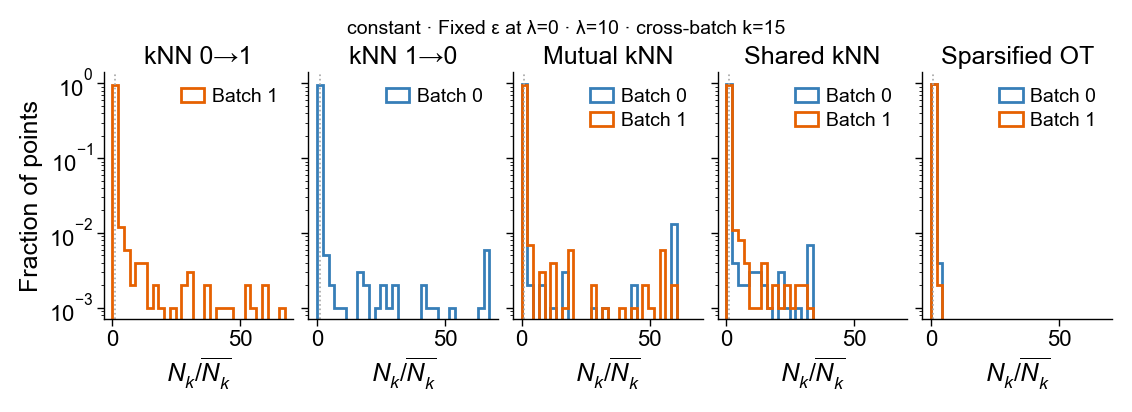

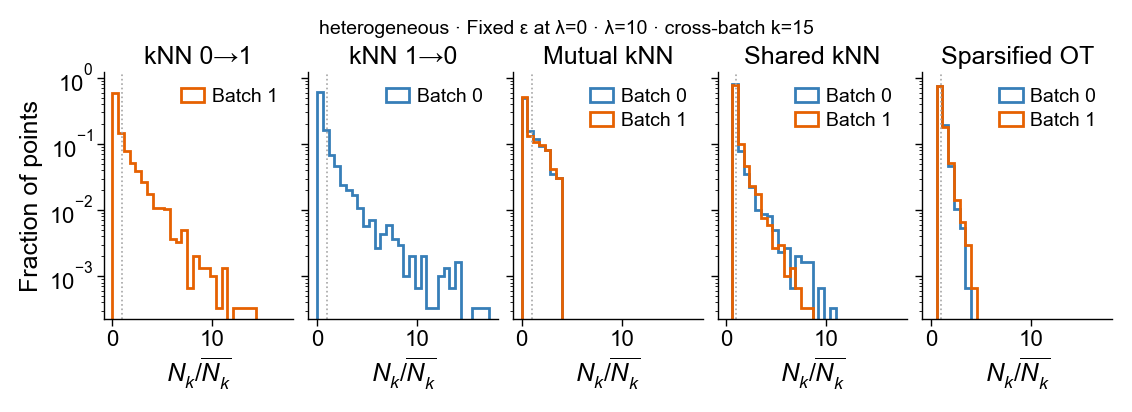

anti_hub_fraction  max_k_occurrence  \
mode          graph      receiving_batch                                        
constant      knn_0_to_1 1                            0.882               989   
              knn_1_to_0 0                            0.947              1000   
              mutual_knn 0                            0.975                15   
                         1                            0.963                15   
              shared_knn 0                            0.000              1000   
                         1                            0.000               989   
              sparse_ot  0                            0.000                53   
                         1                            0.000                48   
heterogeneous knn_0_to_1 1                            0.231               209   
              knn_1_to_0 0                            0.219               256   
              mutual_knn 0                            0.268                15   
                         1                            0.280                15   
              shared_knn 0                            0.000               256   
                         1                            0.000               209   
              sparse_ot  0                            0.000                91   
                         1                            0.000               102   

                                          skewness  
mode          graph      receiving_batch            
constant      knn_0_to_1 1                   7.672  
              knn_1_to_0 0                   7.987  
              mutual_knn 0                   7.585  
                         1                   7.378  
              shared_knn 0                   7.999  
                         1                   7.682  
              sparse_ot  0                   1.644  
                         1                   1.552  
heterogeneous knn_0_to_1 1                   2.752  
              knn_1_to_0 0                   3.800  
              mutual_knn 0                   0.852  
                         1                   0.862  
              shared_knn 0                   4.378  
                         1                   3.251  
              sparse_ot  0                   1.910  
                         1                   2.299

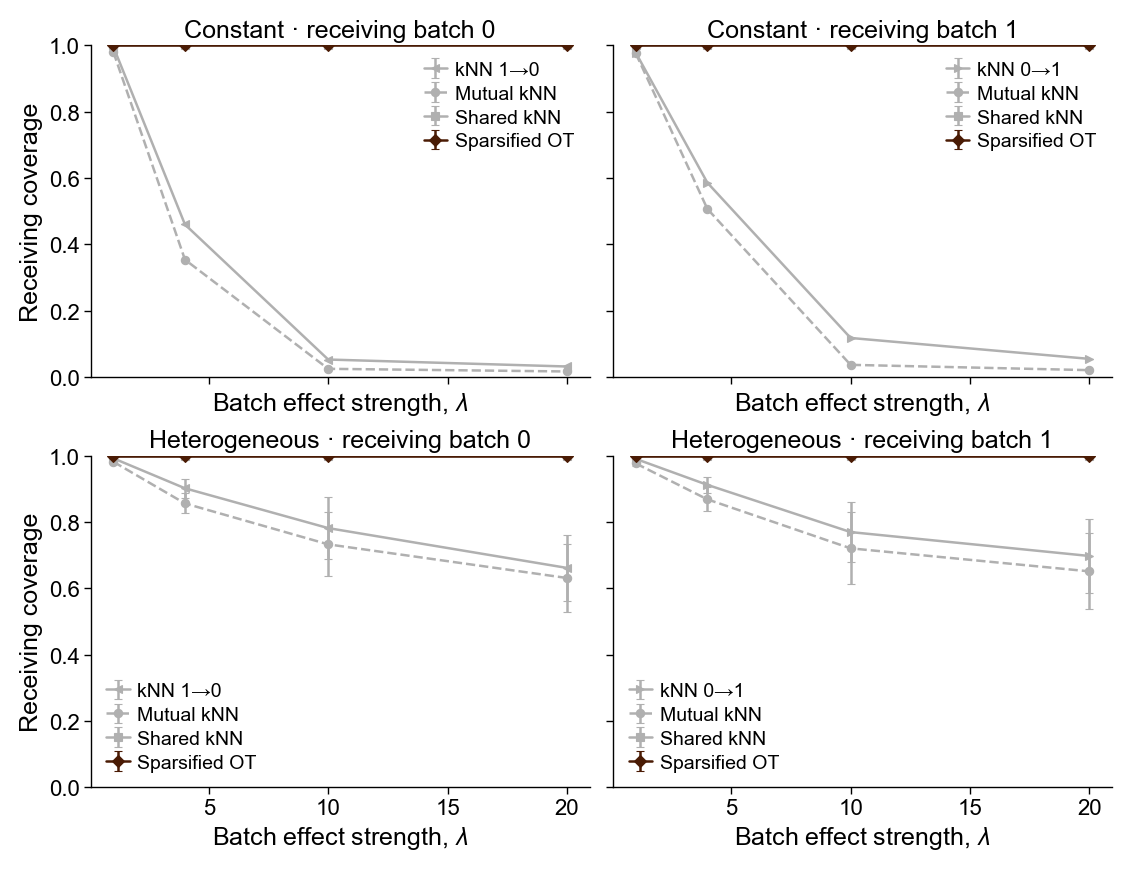

Receiving diagnostics · Adaptive ε · rel_reg=1


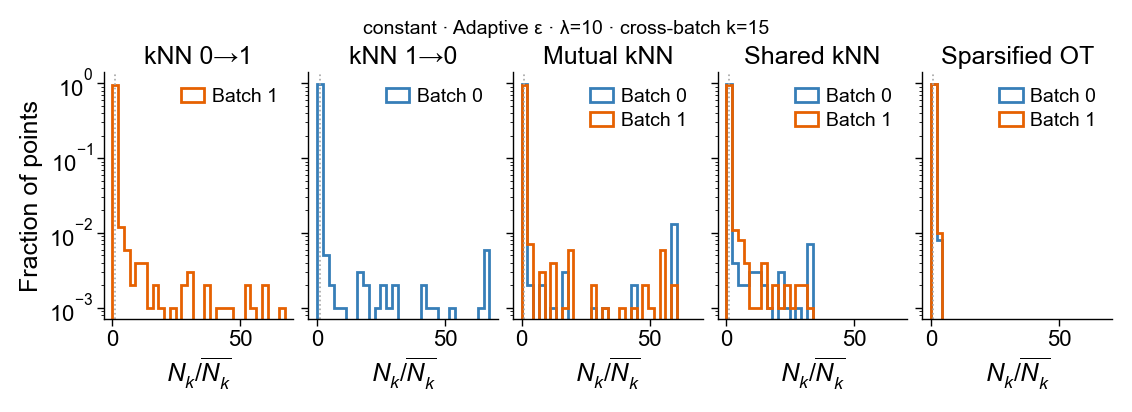

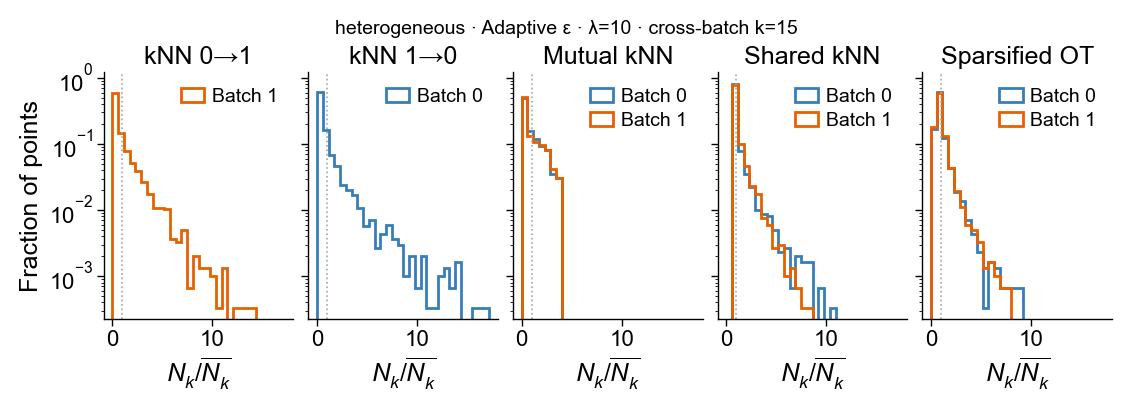

anti_hub_fraction  max_k_occurrence  \
mode          graph      receiving_batch                                        
constant      knn_0_to_1 1                            0.882               989   
              knn_1_to_0 0                            0.947              1000   
              mutual_knn 0                            0.975                15   
                         1                            0.963                15   
              shared_knn 0                            0.000              1000   
                         1                            0.000               989   
              sparse_ot  0                            0.000                63   
                         1                            0.000                59   
heterogeneous knn_0_to_1 1                            0.231               209   
              knn_1_to_0 0                            0.219               256   
              mutual_knn 0                            0.268                15   
                         1                            0.280                15   
              shared_knn 0                            0.000               256   
                         1                            0.000               209   
              sparse_ot  0                            0.000               236   
                         1                            0.000               199   

                                          skewness  
mode          graph      receiving_batch            
constant      knn_0_to_1 1                   7.672  
              knn_1_to_0 0                   7.987  
              mutual_knn 0                   7.585  
                         1                   7.378  
              shared_knn 0                   7.999  
                         1                   7.682  
              sparse_ot  0                   2.004  
                         1                   1.825  
heterogeneous knn_0_to_1 1                   2.752  
              knn_1_to_0 0                   3.800  
              mutual_knn 0                   0.852  
                         1                   0.862  
              shared_knn 0                   4.378  
                         1                   3.251  
              sparse_ot  0                   4.144  
                         1                   3.801

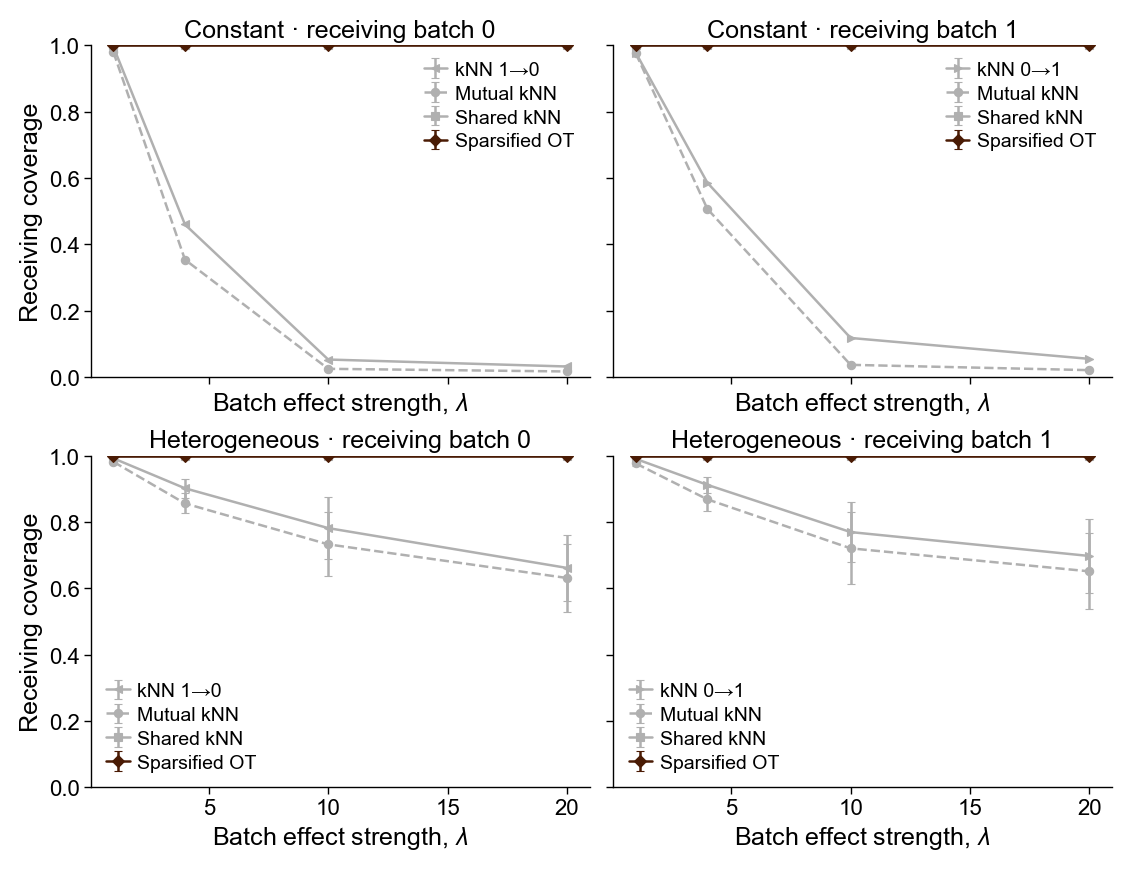

Per-policy statistics, λ=10 counts, seed summaries and settings: results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v2/mnist_parallel_batch_effect/mnist_parallel_batch_effect__seed0__4f85a144/ablation/hubness


In [25]:
if hubness_stats is not None:
    for policy in config.ot.epsilon_policies:
        label = "Fixed ε at λ=0" if policy == "fixed_at_lambda_0" else "Adaptive ε"
        print(f"Receiving diagnostics · {label} · rel_reg={plot_config.rel_reg:g}")
        selected_stats = sweep_only(hubness_stats.loc[hubness_stats.epsilon_policy == policy])
        selected_points = hubness_points.loc[hubness_points.epsilon_policy == policy]
        if not selected_points.empty:
            for mode in config.data.modes:
                occurrence_histograms(selected_points.loc[selected_points["mode"] == mode],
                    title=f"{mode} · {label} · λ=10 · cross-batch k=15")
                plt.show()
            display(selected_stats.loc[selected_stats.magnitude == HUBNESS_MAGNITUDE]
                .groupby(["mode", "graph", "receiving_batch"])
                .agg(anti_hub_fraction=("anti_hub_fraction", "mean"),
                     max_k_occurrence=("max_k_occurrence", "max"), skewness=("skewness", "mean"))
                .round(3))
        fig = receiving_coverage_figure(summarize_coverage(selected_stats), config.data.modes)
        for ax in fig.axes:
            rounded_diagnostic_ylim(ax, probability=True)
        plt.show()
    print(f"Per-policy statistics, λ=10 counts, seed summaries and settings: {hubness_dir}")

## 8. Embedding experiment
Reuse the same OT-tSNE and Scanorama+t-SNE definitions, public scoring APIs, seeds and strict cache
sidecars as the orthogonal notebook. Every noise mode runs every enabled method. Purity uses the
current macro-by-label definition; digit-conditioned kBET uses the configured k.

In [26]:
def score_embedding(meta, embedding, runtime, path, display_method):
    batch_ids = np.r_[np.zeros(len(experiment.labels0), int), np.ones(len(experiment.labels1), int)]
    return {
        **meta,
        "display_method": display_method,
        "purity": compute_neighbor_purity(embedding, experiment.labels),
        "kbet": compute_kbet(embedding, batch_ids, experiment.labels, k=config.evaluation.kbet_k),
        "runtime_seconds": runtime,
        "cache_path": str(path),
    }

### OT-tSNE
Keep both fixed/adaptive ε policies and the configured rel_reg grid. Plans are reused across
embedding seeds within a given mode/corruption/λ case.

In [27]:
def ot_embeddings(x0, x1, mode, magnitude, corruption_seed, embedding_seed):
    records = []
    for rel_reg in experiment.config.ot.rel_reg:
        for epsilon_policy in experiment.config.ot.epsilon_policies:
            plan_key = (mode, corruption_seed, magnitude, rel_reg, epsilon_policy)
            if plan_key not in embedding_plan_cache:
                embedding_plan_cache[plan_key] = experiment.compute_policy_plan(x0, x1, mode, rel_reg, epsilon_policy, return_artifacts=True)
            plan, artifacts = embedding_plan_cache[plan_key]
            display_method = f'OT-tSNE ({epsilon_policy}, rel_reg={rel_reg:g})'
            path = experiment.cache_path(mode, magnitude, 'ot', 'tsne', corruption_seed, embedding_seed, epsilon_policy, rel_reg, experiment.config.ot.ot_effective_k)
            meta = dict(mode=mode, magnitude=magnitude, method='ot', backend='tsne', corruption_seed=corruption_seed, embedding_seed=embedding_seed, rel_reg=rel_reg, epsilon=float(artifacts['epsilon']), epsilon_policy=epsilon_policy, effective_k=experiment.config.ot.ot_effective_k, n_jobs=TSNE_N_JOBS)
            embedding, runtime = experiment.load_or_compute(path, lambda plan=plan, embedding_seed=embedding_seed, x0=x0, x1=x1: compute_ot_tsne_embedding_from_plan(plan, effective_k=experiment.config.ot.ot_effective_k, random_state=embedding_seed, n_epochs=experiment.config.embedding.n_epochs, early_exaggeration_iter=experiment.config.embedding.early_exaggeration_iter, init='random', backend='tsne', x_joint=np.vstack([x0, x1]), n_jobs=TSNE_N_JOBS), meta)
            records.append(score_embedding(meta, embedding, runtime, path, display_method))
    return records

### Scanorama + t-SNE
Exact Scanorama matching, 50 integrated dimensions, then t-SNE with perplexity 30.

In [28]:
def scanorama_embeddings(x0, x1, mode, magnitude, corruption_seed, embedding_seed):
    records = []
    if experiment.config.competitors.run_scanorama_50_tsne:
        display_method, key = ('Scanorama + t-SNE (50d)', 'scanorama-50-tsne')
        path = experiment.cache_path(mode, magnitude, key, 'tsne', corruption_seed, embedding_seed)
        meta = dict(mode=mode, magnitude=magnitude, method=key, backend='tsne', corruption_seed=corruption_seed, embedding_seed=embedding_seed, epsilon_policy=None, rel_reg=None, effective_k=None, integration_dim=50, perplexity=30.0, n_epochs=experiment.config.embedding.n_epochs)
        embedding, runtime = experiment.load_or_compute(path, lambda embedding_seed=embedding_seed, x0=x0, x1=x1: compute_scanorama_then_tsne_embedding_from_arrays(x0, x1, scanorama_dim=50, random_state=embedding_seed, perplexity=30.0, scanorama_kwargs={'approx': False}, n_iter=experiment.config.embedding.n_epochs, early_exaggeration_iter=experiment.config.embedding.early_exaggeration_iter, backend='tsne', n_jobs=TSNE_N_JOBS), meta)
        records.append(score_embedding(meta, embedding, runtime, path, display_method))
    return records

### MultiMAP: centered and uncentered
`multimap_profile` still chooses native defaults or k=15. `multimap_preprocessing` defaults to both
centered and uncentered, and each gets a distinct method/cache ID.
Centered uses the wrapper's native scaling and centered PCA. Uncentered uses the existing preset:
no scaling, no per-batch centering, and TruncatedSVD. Thus this comparison includes both centering
and scaling differences; it is not a pure centering-only ablation. Other layout parameters stay
at native defaults. In particular, smoke mode does not override MultiMAP epochs.

In [29]:
def multimap_embeddings(x0, x1, mode, magnitude, corruption_seed, embedding_seed):
    records = []
    if not config.competitors.run_multimap:
        return records
    k = 15 if config.competitors.multimap_profile == "k15" else None
    for preprocessing in config.competitors.multimap_preprocessing:
        backend = "native-defaults" if preprocessing == "centered" else "uncentered-svd-defaults"
        kwargs = {} if k is None else {"n_neighbors": k}
        if preprocessing == "uncentered":
            kwargs.update(scale=False, center_batches=False, use_native_scaling=False)
        meta = dict(
            mode=mode,
            magnitude=magnitude,
            method="multimap",
            backend=backend,
            corruption_seed=corruption_seed,
            embedding_seed=embedding_seed,
            epsilon_policy=None,
            rel_reg=None,
            effective_k=k,
            preprocessing=preprocessing,
            multimap_profile=config.competitors.multimap_profile,
        )
        path = experiment.cache_path(
            mode, magnitude, "multimap", backend, corruption_seed, embedding_seed, k=k
        )
        embedding, runtime = experiment.load_or_compute(
            path,
            partial(
                compute_multimap_embedding_from_arrays,
                x0,
                x1,
                random_state=embedding_seed,
                **kwargs,
            ),
            meta,
        )
        records.append(score_embedding(meta, embedding, runtime, path, "MultiMAP"))
    return records

In [30]:
def prepare_joint_gallery():
    for mode in config.data.modes:
        x0, x1 = experiment.make_batches(mode, plot_config.magnitude, plot_config.corruption_seed)
        path = experiment.cache_path(mode, plot_config.magnitude, 'joint-tsne', 'tsne', plot_config.corruption_seed, plot_config.embedding_seed)
        metadata = dict(mode=mode, method='joint-tsne', magnitude=plot_config.magnitude, corruption_seed=plot_config.corruption_seed, embedding_seed=plot_config.embedding_seed, perplexity=30.0, pca_components=50, n_iter=config.embedding.n_epochs, early_exaggeration_iter=config.embedding.early_exaggeration_iter, n_jobs=TSNE_N_JOBS)
        experiment.load_or_compute(path, partial(compute_tsne_embedding_from_arrays, x0, x1, random_state=plot_config.embedding_seed, perplexity=30.0, pca_components=50, n_iter=config.embedding.n_epochs, early_exaggeration_iter=config.embedding.early_exaggeration_iter, n_jobs=TSNE_N_JOBS), metadata)

In [31]:
if RUN_EXPERIMENT:
    records, embedding_plan_cache = [], {}
    for mode in config.data.modes:
        for corruption_seed in config.corruption.corruption_seeds:
            for magnitude in config.corruption.magnitudes:
                x0, x1 = experiment.make_batches(mode, magnitude, corruption_seed)
                embedding_plan_cache.clear()
                for embedding_seed in config.embedding.embedding_seeds:
                    for method in (ot_embeddings, scanorama_embeddings, multimap_embeddings):
                        records.extend(
                            method(x0, x1, mode, magnitude, corruption_seed, embedding_seed)
                        )
                print(f"Completed {mode}, corruption seed {corruption_seed}, λ={magnitude:g}")
    experiment.results = label_methods(pd.DataFrame(records))
    experiment.save_stage("embedding")
    # Cache the same joint PCA-50/t-SNE control separately for each noise mode.
    prepare_joint_gallery()
    results = experiment.results
else:
    results = runs.metrics
print(f"{len(results)} per-seed embedding evaluations; complete table saved on disk.")

630 per-seed embedding evaluations; complete table saved on disk.


### Representative embeddings: both modes and both MultiMAP variants
The gallery reads cached coordinates at the chosen λ/seeds. Each mode has a batch-colored row
and a digit-colored row, including joint t-SNE, OT-tSNE and both MultiMAP variants. Choose a gallery
λ/seed/rel_reg that is present in the configured embedding grid.

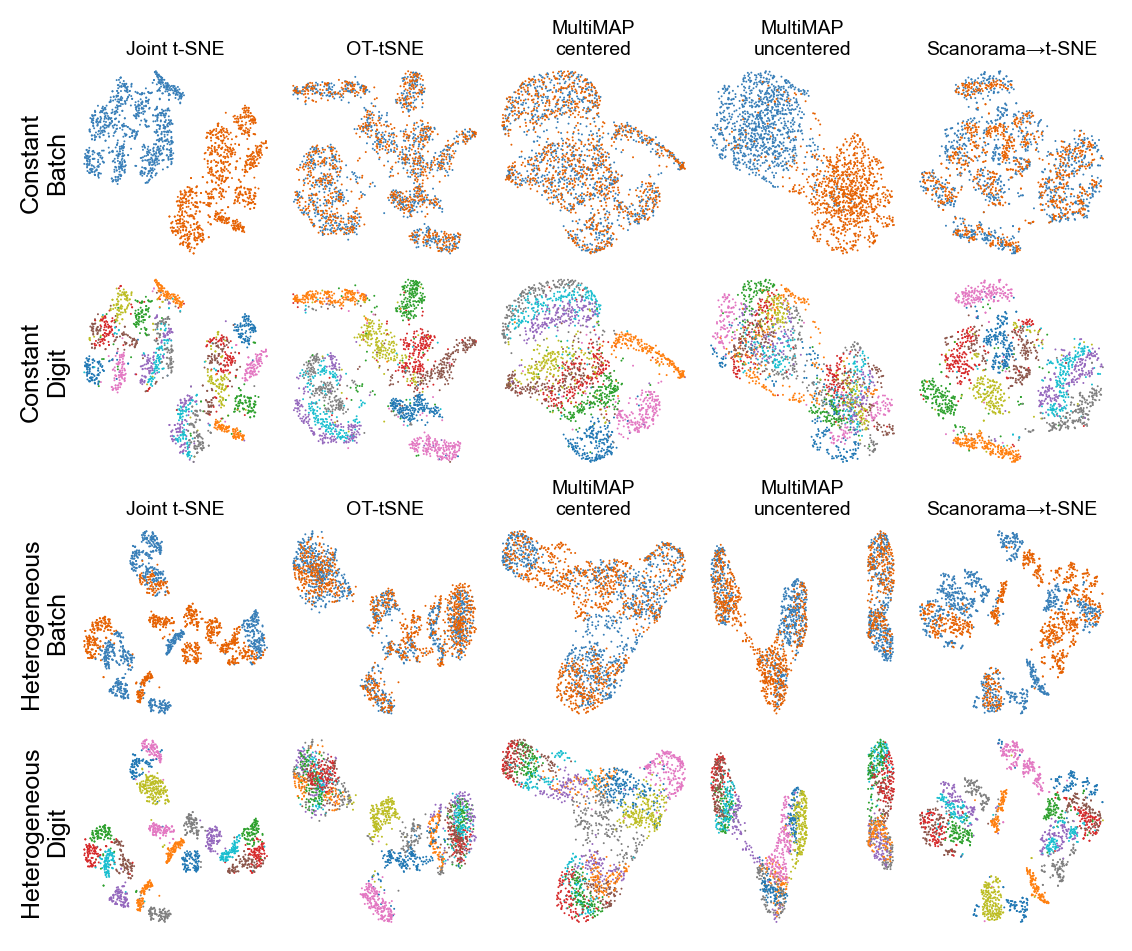

In [32]:
parallel_drawing.embedding_gallery(experiment.run_dir, plot_config)
plt.show()

## 9. Aggregate and inspect results
First average embedding seeds within each corruption draw, then summarize across corruption draws.
The identical aggregation code keeps mode, method ID, preprocessing, rel_reg and ε policy explicit.
Both noise modes appear in the purity/kBET plots; solid/dashed MultiMAP curves distinguish
centered/uncentered preprocessing. Constant-mode corruption draws are identical constructions;
its seed variation measures embedding variability, not new noise realizations.

In [33]:
if RUN_EXPERIMENT:
    if "preprocessing" not in experiment.results:
        experiment.results["preprocessing"] = None
    experiment.per_corruption_summary = (
        experiment.results.groupby(
            [
                "mode",
                "magnitude",
                "method_id",
                "method",
                "display_method",
                "epsilon_policy",
                "rel_reg",
                "effective_k",
                "preprocessing",
                "corruption_seed",
            ],
            dropna=False,
        )
        .agg(
            purity=("purity", "mean"),
            purity_embedding_sd=("purity", "std"),
            kbet=("kbet", "mean"),
            kbet_embedding_sd=("kbet", "std"),
            n_embedding_seeds=("embedding_seed", "size"),
        )
        .reset_index()
    )
    experiment.summary = (
        experiment.per_corruption_summary.groupby(
            [
                "mode",
                "magnitude",
                "method_id",
                "method",
                "display_method",
                "epsilon_policy",
                "rel_reg",
                "effective_k",
                "preprocessing",
            ],
            dropna=False,
        )
        .agg(
            purity=("purity", "mean"),
            purity_std=("purity", "std"),
            purity_embedding_sd_mean=("purity_embedding_sd", "mean"),
            kbet=("kbet", "mean"),
            kbet_std=("kbet", "std"),
            kbet_embedding_sd_mean=("kbet_embedding_sd", "mean"),
            n_corruption_seeds=("corruption_seed", "size"),
        )
        .reset_index()
    )
    experiment.save_stage("summary")
else:
    print("Using saved artifacts for this stage.")

Using saved artifacts for this stage.


In [34]:
# Reload after aggregation; the following cell provides the full metrics comparison.
runs = load_selected_ablation()
print("Saved run:", experiment.run_dir)

Saved run: results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v2/mnist_parallel_batch_effect/mnist_parallel_batch_effect__seed0__4f85a144


### Embedding purity and batch mixing
Compare saved OT-tSNE, Scanorama+t-SNE, and MultiMAP results for each configured rel_reg.
Average embedding seeds within each corruption seed, then show mean ± SD across corruption seeds.
Fixed and adaptive OT use matched embedding seeds; λ=0 is excluded from the sweep display.
The compact table shows the first and last experimental λ values; full tables remain saved.


Fresh embeddings · rel_reg=1


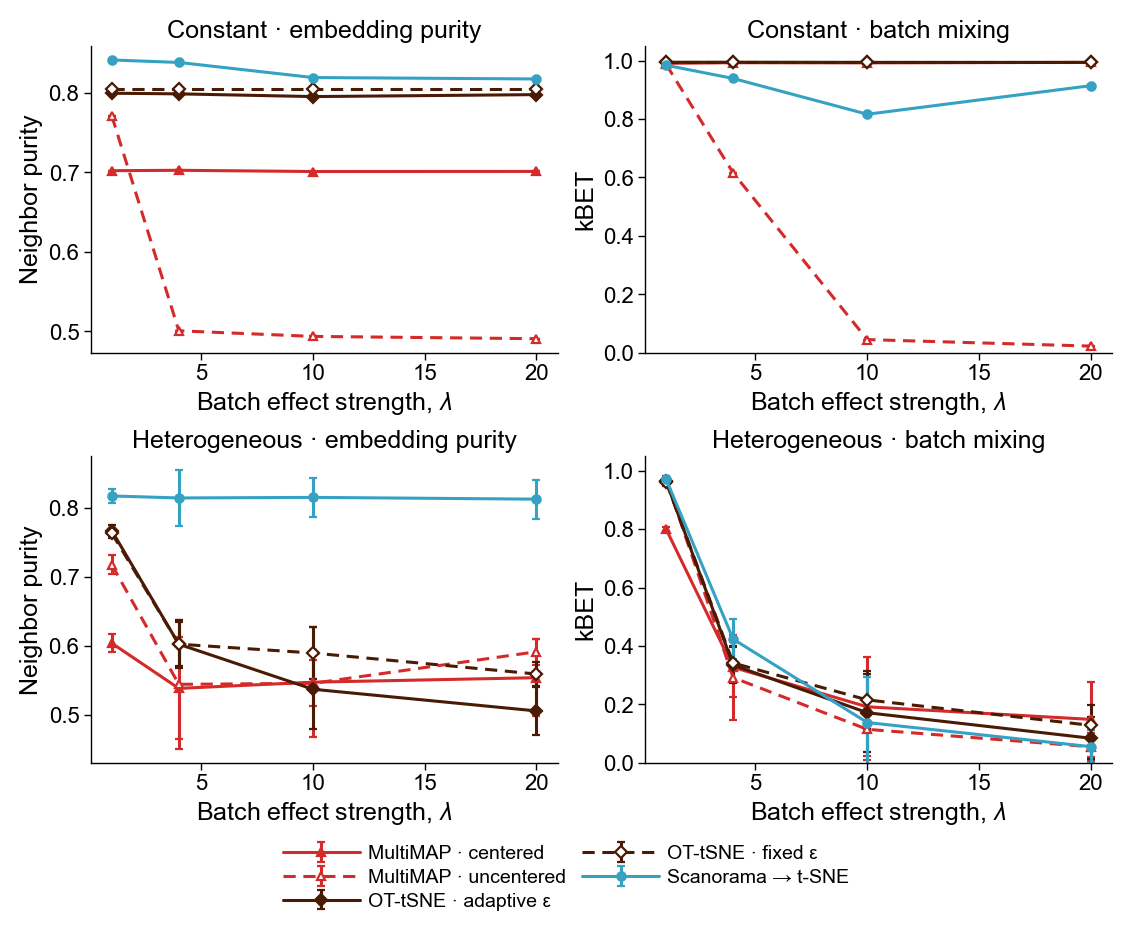

Fresh embeddings · rel_reg=10


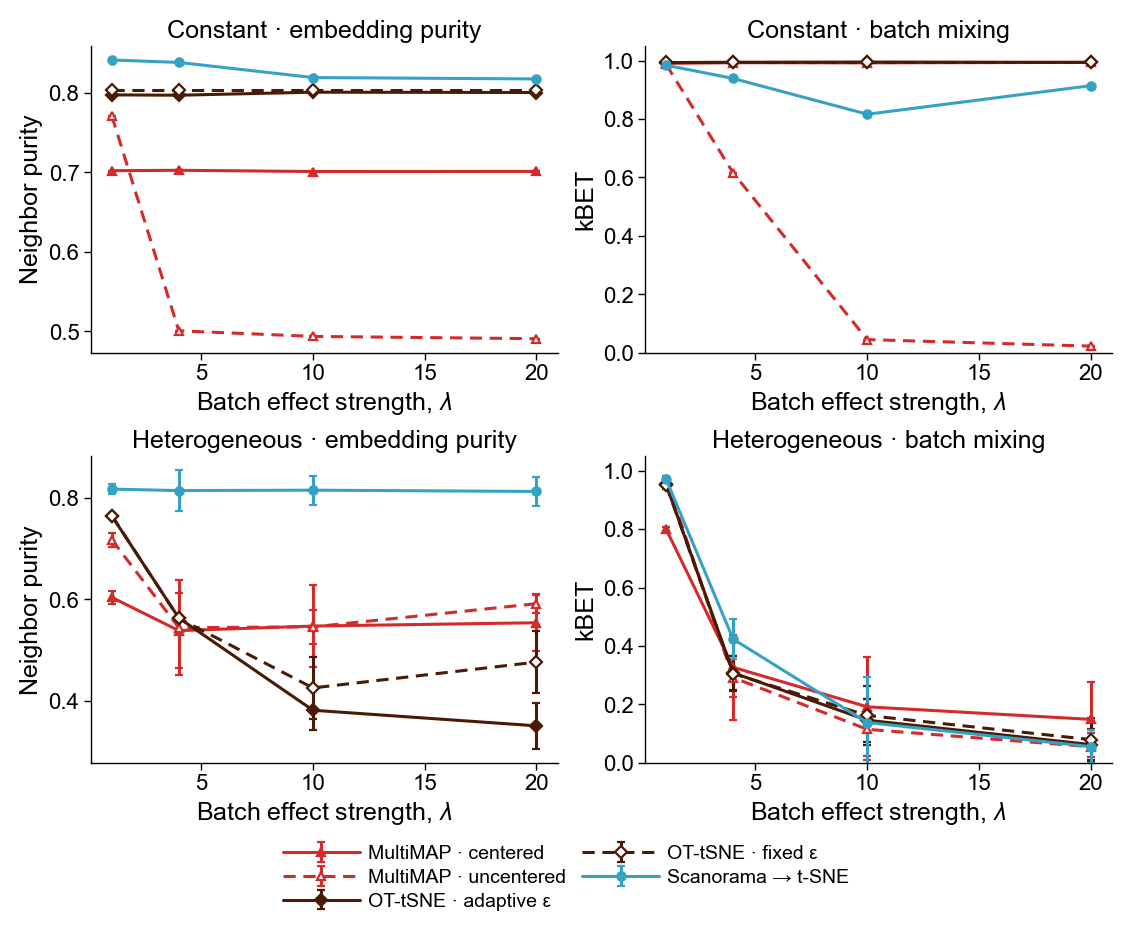

,mode,magnitude,display_method,purity,purity_std,purity_embedding_sd_mean,kbet,kbet_std,kbet_embedding_sd_mean
10,constant,1.0,OT-tSNE · adaptive ε · rel_reg=1,0.799,0.000,0.003,0.994,0.000,0.001
12,constant,1.0,OT-tSNE · fixed ε · rel_reg=1,0.805,0.000,0.007,0.995,0.000,0.001
31,constant,20.0,OT-tSNE · adaptive ε · rel_reg=1,0.798,0.000,0.004,0.994,0.000,0.000
33,constant,20.0,OT-tSNE · fixed ε · rel_reg=1,0.805,0.000,0.007,0.995,0.000,0.001
45,heterogeneous,1.0,OT-tSNE · adaptive ε · rel_reg=1,0.767,0.008,0.005,0.964,0.014,0.004
47,heterogeneous,1.0,OT-tSNE · fixed ε · rel_reg=1,0.763,0.007,0.006,0.963,0.015,0.002
66,heterogeneous,20.0,OT-tSNE · adaptive ε · rel_reg=1,0.506,0.035,0.002,0.084,0.071,0.002
68,heterogeneous,20.0,OT-tSNE · fixed ε · rel_reg=1,0.559,0.017,0.005,0.128,0.068,0.003


In [35]:
quality = sweep_only(experiment.summary if RUN_EXPERIMENT else runs.summary)
for rel_reg in config.ot.rel_reg:
    selected = quality.loc[(quality.method != "ot") | np.isclose(quality.rel_reg, rel_reg)]
    print(f"Fresh embeddings · rel_reg={rel_reg:g}")
    # Reuse the repository's method colors, markers and fixed/adaptive line styles.
    from ne_aligned_utils.paper.figures import parallel_synthetic as comparison_drawing
    fig = comparison_drawing.metrics_figure(selected, config.data.modes, rel_reg)
    plt.show()
quality_preview = quality.loc[(quality.method == "ot") &
    np.isclose(quality.rel_reg, plot_config.rel_reg) &
    quality.magnitude.isin([min(DISPLAY_MAGNITUDES), max(DISPLAY_MAGNITUDES)])]
display(quality_preview[["mode", "magnitude", "display_method", "purity", "purity_std",
    "purity_embedding_sd_mean", "kbet", "kbet_std", "kbet_embedding_sd_mean"]].round(3))


### Results without fixed ε
Keep adaptive-ε OT and all competitors, with the same colors, axes, and uncertainty summaries
as the full comparison above. The saved results retain both ε policies.

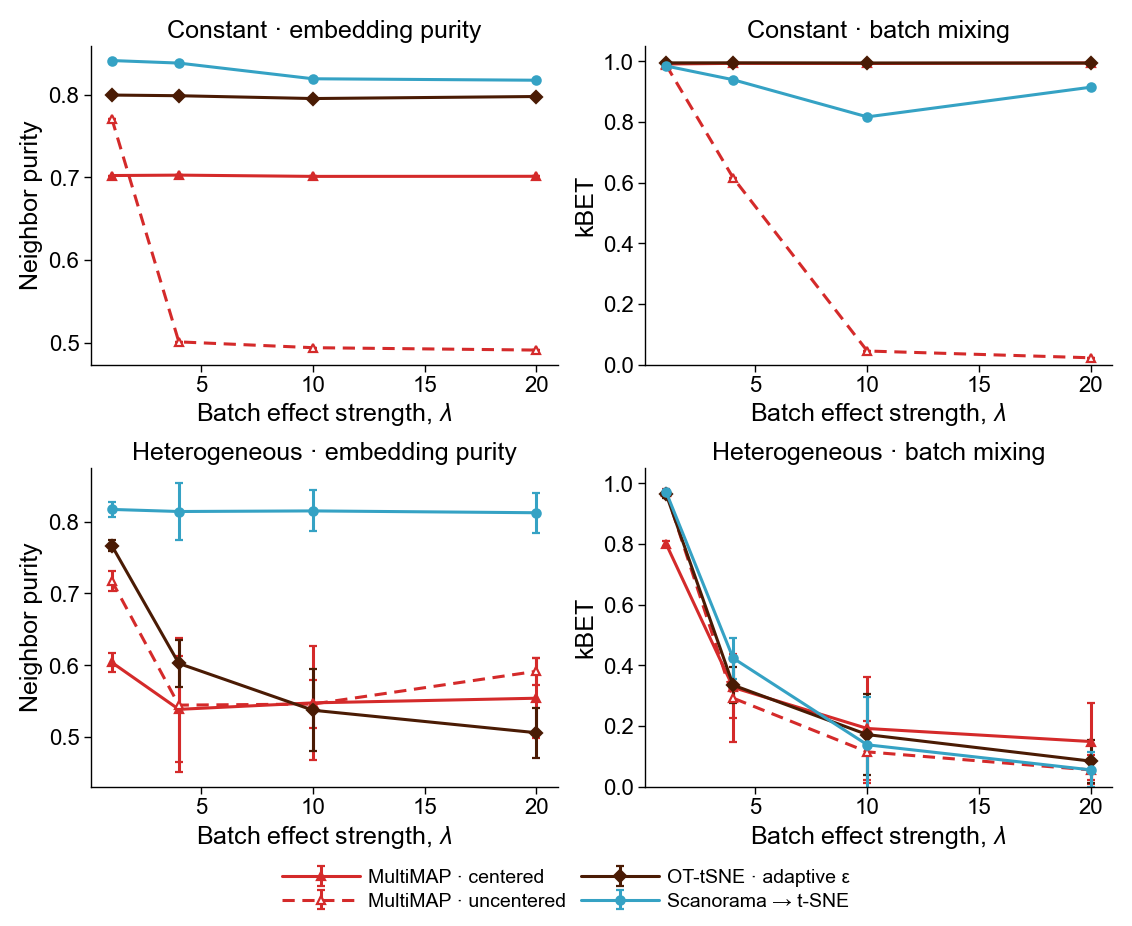

In [36]:
adaptive_summary = runs.summary.loc[
    ~runs.summary["epsilon_policy"].eq("fixed_at_lambda_0")
]
parallel_drawing.metrics_figure(sweep_only(adaptive_summary), config.data.modes, plot_config.rel_reg)
plt.show()

## 10. Reproduce comparison figures from saved results
The explicit run was reloaded through the strict artifact loader. We call the same policy,
affinity, gallery and metric panel functions as `build_parallel_figures()`, passing positive-λ
tables for the sweep panels. This keeps the canonical layouts with **both** noise modes; the
archived λ=0 rows remain intact for calibration and reference checks.
The separate parallel builder does not modify or relabel the orthogonal manuscript figure.
`SAVE_PAPER_FIGURE=True` saves under `results/paper_figures/synthetic_experiment/parallel_pc1/<run-name>/`.
Otherwise figures are displayed only. Rendering never computes OT or an embedding.

The hierarchy follows the orthogonal experiment: a root config/construction plus `constant/` and
`heterogeneous/`, each with diagnostics, raw/per-corruption/summary metric CSVs, and per-method
embedding caches with JSON sidecars. Reuse the same config and `RUN_NAME` to reload a completed run.

epsilon_policies: constant and heterogeneous · mnist_parallel_batch_effect__seed0__4f85a144


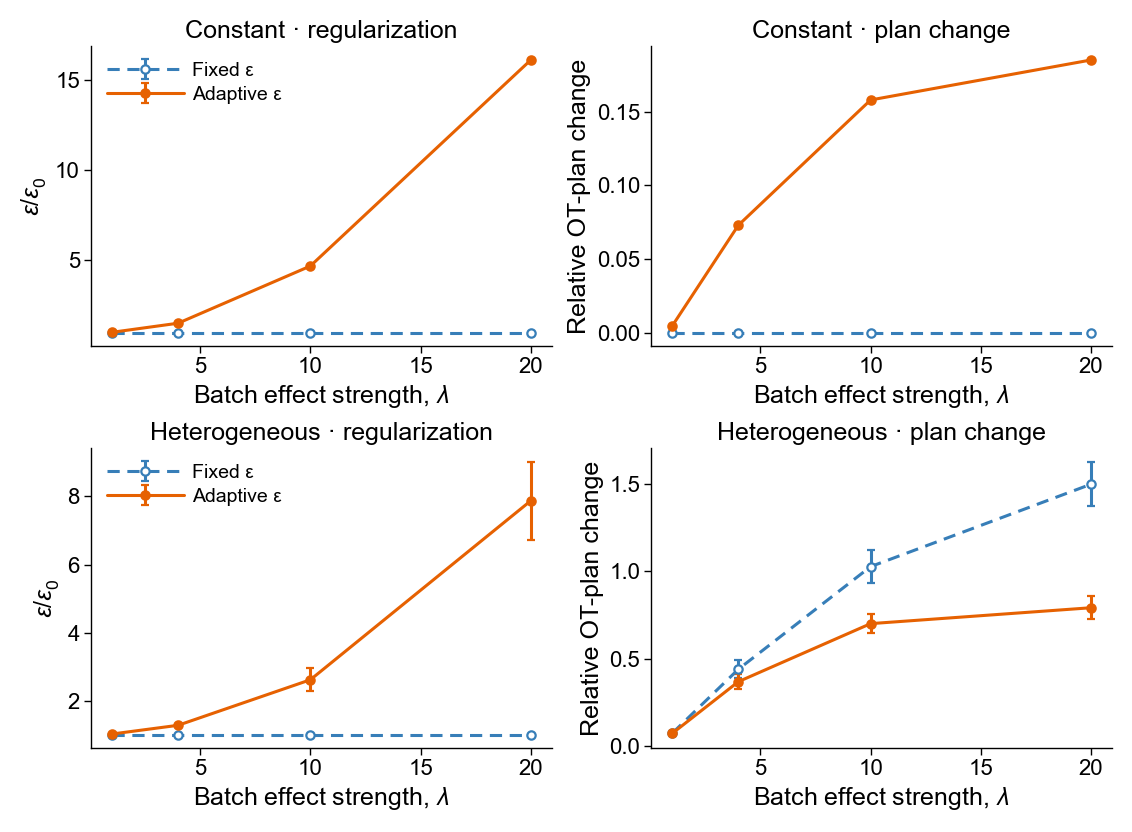

cross_batch_affinities: constant and heterogeneous · mnist_parallel_batch_effect__seed0__4f85a144


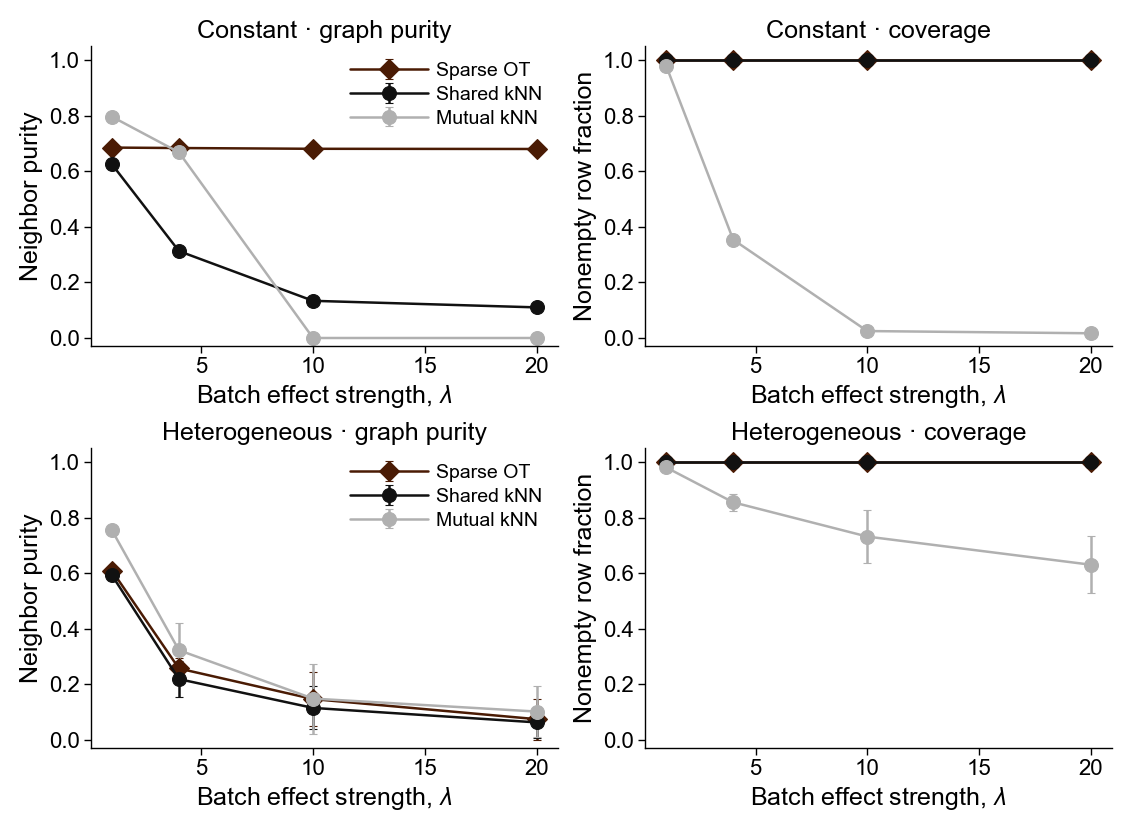

embeddings: constant and heterogeneous · mnist_parallel_batch_effect__seed0__4f85a144


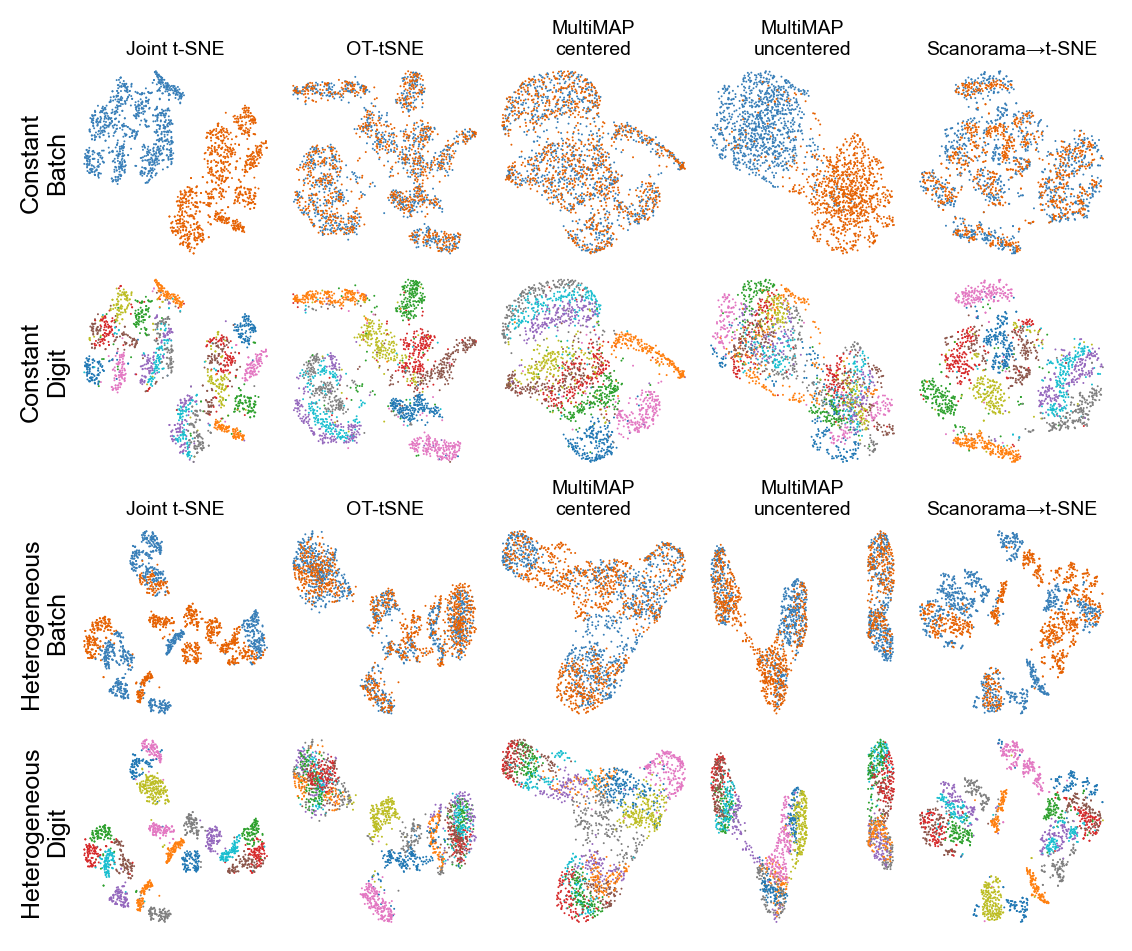

embedding_metrics: constant and heterogeneous · mnist_parallel_batch_effect__seed0__4f85a144


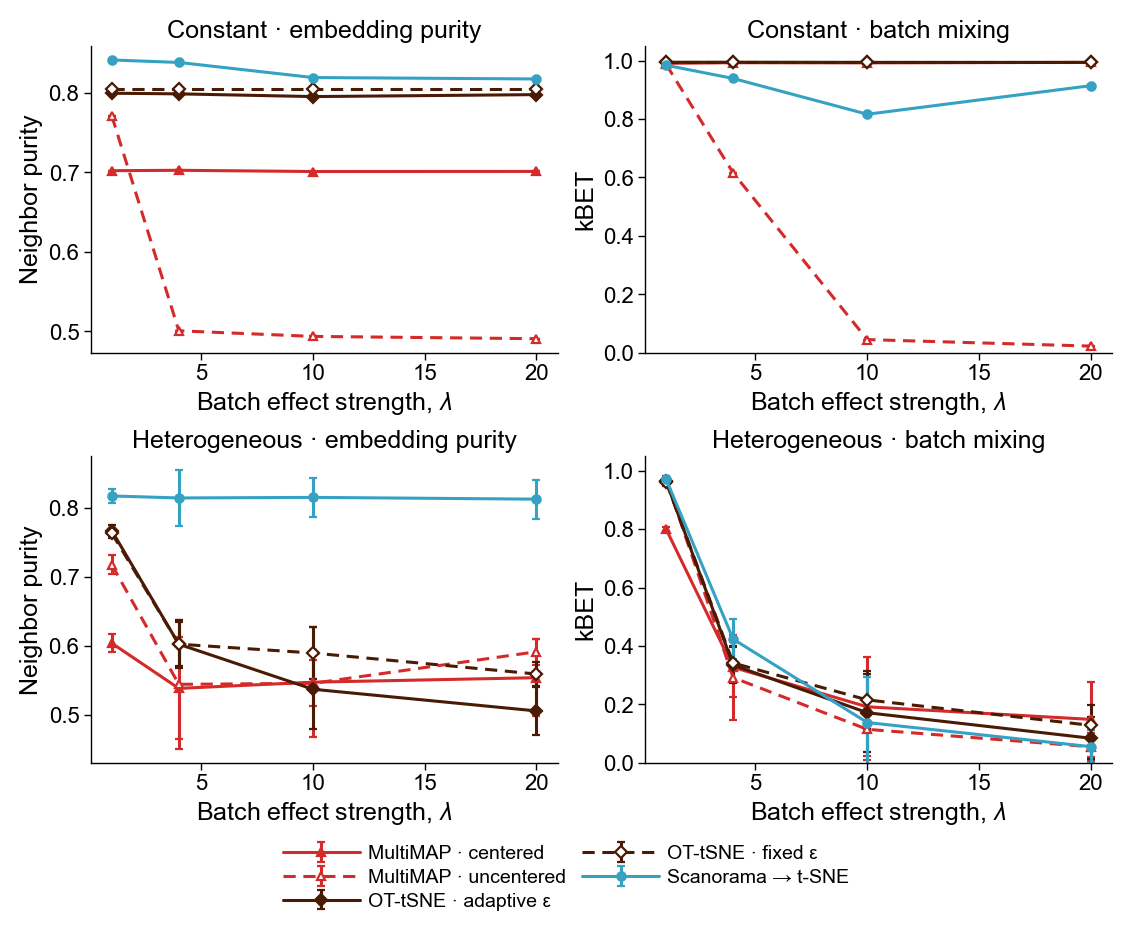

In [37]:
output_dir = (
    (ROOT / "results/paper_figures/synthetic_experiment/parallel_pc1" / experiment.run_dir.name)
    if SAVE_PAPER_FIGURE
    else None
)
# Use the canonical panel functions with an explicit positive-lambda display selection.
figures = {
    "epsilon_policies": parallel_drawing.policy_figure(sweep_only(runs.cost), config.data.modes, plot_config.rel_reg),
    "cross_batch_affinities": parallel_drawing.affinity_figure(sweep_only(runs.affinity), sweep_only(runs.knn), config.data.modes, plot_config.rel_reg),
    "embeddings": parallel_drawing.embedding_gallery(experiment.run_dir, plot_config),
    "embedding_metrics": parallel_drawing.metrics_figure(sweep_only(runs.summary), config.data.modes, plot_config.rel_reg),
}
if output_dir is not None:
    for name, fig in figures.items():
        layout.save_figure(fig, f"parallel_pc1_{name}", root=output_dir, preview=False, close=False)
for name, fig in figures.items():
    print(f"{name}: constant and heterogeneous · {experiment.run_dir.name}")
    display(fig)
    plt.close(fig)

## 11. Appendix composites — ε ablation at `rel_reg=1`
Use the same explicitly selected saved run. Each mode has six panels: numerical ε, full-plan
TV against each policy's own zero reference, fixed-versus-adaptive TV at the same λ, Sparse OT
Jaccard against zero, OT-tSNE cross-affinity Jaccard against zero, and symmetric cross-batch graph
purity. Sparse OT uses the row/column top-15 union; OT-tSNE uses its actual cross-block selection.

Jaccard counts shared edges divided by all distinct edges in either graph; it does not compare
weights. Purity averages unweighted node scores within each batch, then equally across batches.
Only positive λ values are displayed, with mean ± SD across corruption seeds and fitted, rounded
y-ranges. `SAVE_APPENDIX_FIGURES` exports PNG/PDF files to this run's
`figures/appendix_eps_ablation/` directory. No method fitting occurs here.


Appendix · constant · rel_reg=1 · mnist_parallel_batch_effect__seed0__4f85a144


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


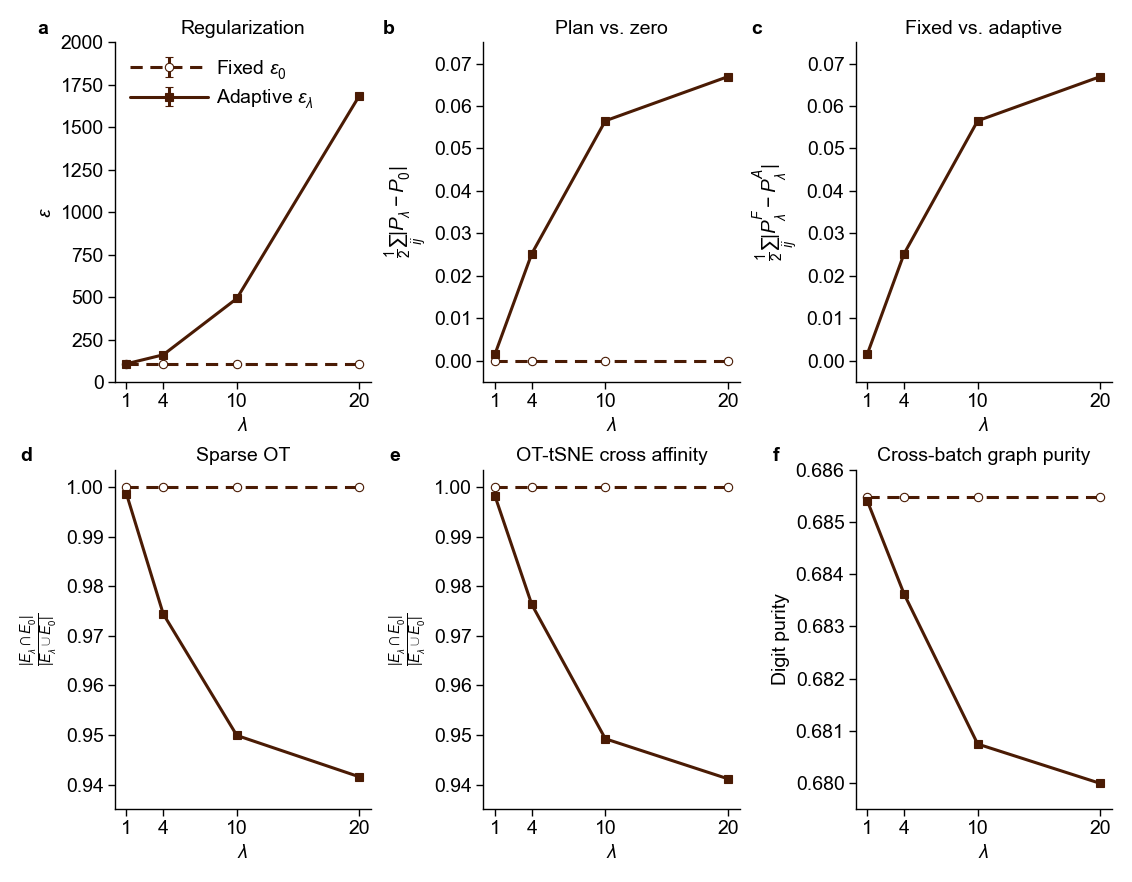

Appendix · heterogeneous · rel_reg=1 · mnist_parallel_batch_effect__seed0__4f85a144


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


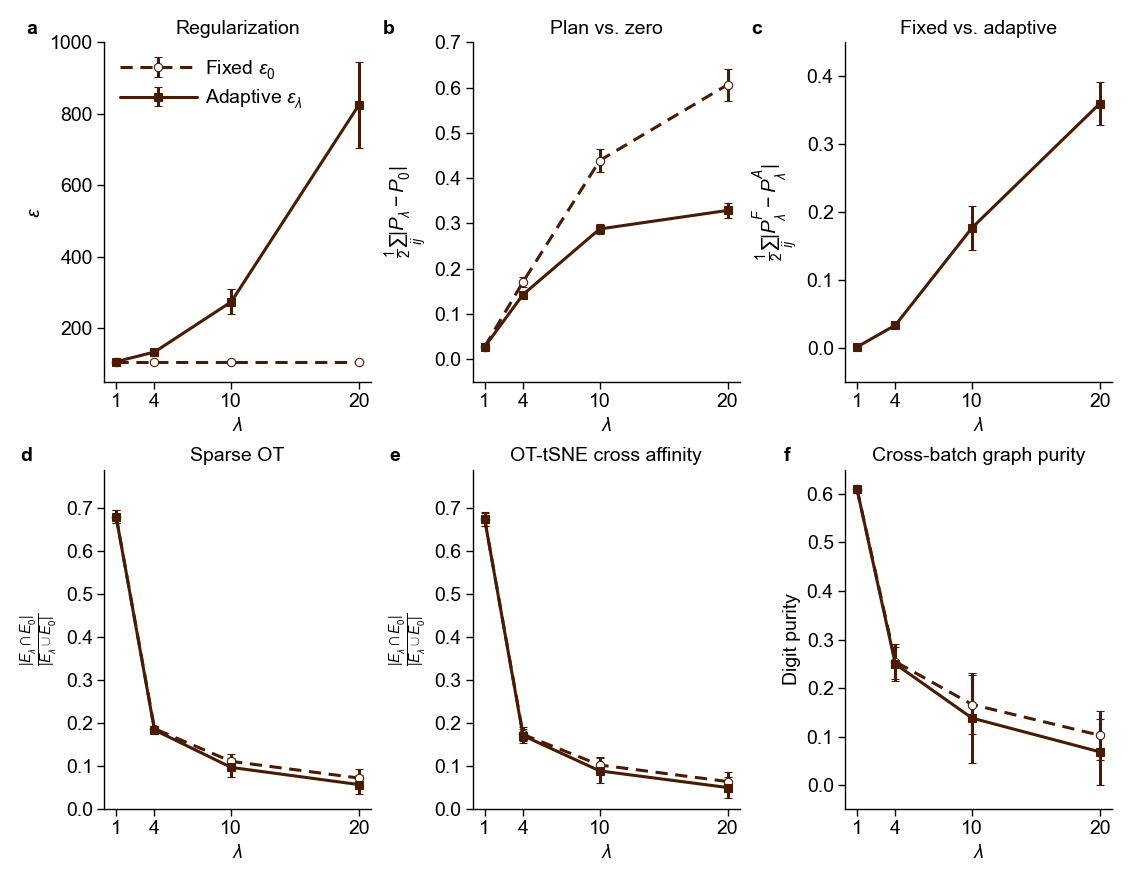

Appendix PNG/PDF files: results/synthetic_eps_ablation/benchmark-defaults-eps0-20261108-v2/mnist_parallel_batch_effect/mnist_parallel_batch_effect__seed0__4f85a144/figures/appendix_eps_ablation


In [38]:
SAVE_APPENDIX_FIGURES = True
APPENDIX_REL_REG = 1.0
appendix_dir = experiment.run_dir / "figures/appendix_eps_ablation"
for mode in config.data.modes:
    plan_data = cost.loc[(cost["mode"] == mode) & np.isclose(cost.rel_reg, APPENDIX_REL_REG)]
    graph_data = affinity.loc[(affinity["mode"] == mode) & np.isclose(affinity.rel_reg, APPENDIX_REL_REG)]
    fig, axes = plt.subplots(2, 3, figsize=layout.full_width(4.25), layout="constrained")
    specifications = (
        (plan_data, "epsilon", r"$\epsilon$", "Regularization", False),
        (plan_data, "tv_to_lambda0", r"$\frac{1}{2}\sum_{ij}|P_\lambda-P_0|$", "Plan vs. zero", False),
        (plan_data, "fixed_vs_adaptive_tv", r"$\frac{1}{2}\sum_{ij}|P_\lambda^F-P_\lambda^A|$", "Fixed vs. adaptive", False),
        (graph_data, "shared_or_jaccard_to_lambda0", r"$\frac{|E_\lambda\cap E_0|}{|E_\lambda\cup E_0|}$", "Sparse OT", True),
        (graph_data, "ot_tsne_cross_jaccard_to_lambda0", r"$\frac{|E_\lambda\cap E_0|}{|E_\lambda\cup E_0|}$", "OT-tSNE cross affinity", True),
        (graph_data, "eot_shared_or_symmetric_digit_purity", "Digit purity", "Cross-batch graph purity", True),
    )
    for ax, (frame, metric, ylabel, title, bounded) in zip(axes.flat, specifications):
        policy_panel(ax, frame, metric, ylabel, title, bounded=bounded)
        rounded_diagnostic_ylim(ax, probability=bounded)
        if metric in {"shared_or_jaccard_to_lambda0", "ot_tsne_cross_jaccard_to_lambda0"}:
            # Jaccard can equal 1: keep markers/error-bar caps clear of the top boundary.
            lower, upper = ax.get_ylim()
            headroom = .05 * (upper - lower)
            quantum = 5 * 10.0 ** (np.floor(np.log10(headroom)) - 1)
            upper = np.ceil((max(upper, ax.dataLim.ymax) + headroom) / quantum) * quantum
            ax.set_ylim(lower, float(upper))
    axes[0, 0].legend(fontsize=drawing.PANEL_TITLE_PT, handlelength=4)
    for letter, ax, (_, _, _, title, _) in zip("abcdef", axes.flat, specifications):
        drawing.set_panel_title(ax, title, fontsize=drawing.PANEL_TITLE_PT,
            letter=letter, centred=True)
        ax.tick_params(labelsize=drawing.PANEL_TITLE_PT)
        ax.xaxis.label.set_size(drawing.PANEL_TITLE_PT)
        ax.yaxis.label.set_size(drawing.PANEL_TITLE_PT)
    fig.canvas.draw()
    fig.set_layout_engine("none")  # Freeze positions before the paper's title alignment pass.
    drawing.align_panel_titles(fig)
    print(f"Appendix · {mode} · rel_reg=1 · {experiment.run_dir.name}")
    if SAVE_APPENDIX_FIGURES:
        layout.save_figure(fig, f"eps_ablation_{mode}__rel_reg_1", root=appendix_dir,
            formats=("png", "pdf"), preview=False, close=False)
    plt.show()
if SAVE_APPENDIX_FIGURES:
    print(f"Appendix PNG/PDF files: {appendix_dir}")
